# 6. Disease Tissue Signal: cfRNA/cfDNA Literature vs NM

- For each disease's **tissue of interest** (`EDA/disease_tissue_literature.md`, re-evaluated by C1/C2), one table/figure shows how many of that tissue's markers the literature (source study, other cfRNA, cfDNA) and NM each captured.
- Group DEG is not used: the available DESeq2 results do not reproduce the source studies' analyses (sample set, method, covariates), so they are an inappropriate baseline.
  - NM vs group comparison is handled by the Moore matched comparison (nb7).

| Source | Definition |
|---|---|
| Literature (Lit) | Genes the disease's cfRNA paper explicitly attributed to that tissue ([FT] items in md Part S) |
| NM | BH q<0.05 up in >= 1 patient, 0 same-batch HC |
| NM new | NM genes that are not literature-named markers |

- Tissue marker panels (`notebookscripts/hpa_panels.py` `tct_panel_table`, HPA 25.1):
  - Cell-type assignment from HPA tissue cell type (cell-type enrichment within tissue); keep only genes that also pass body-wide specificity (organ tissue specificity or cell-type single cell specificity; enriched / group enriched / enhanced).
  - Single cell enriched genes of that cell type are included even if missing from tissue cell type.
  - Up to 200 per panel: enriched first, then by HPA specificity score.
  - Panels without HPA tissue cell type (placenta, esophagus, small intestine, brain, platelet) use the single cell enriched rule with the same cap.
  - Then **plasma specificity filter**: genes with detection rate >= `PLASMA_MAX_HC_DETECT` (90%) across the full HC pool are treated as always present in plasma and removed.
- Literature-named marker genes **always** appear in tables and figures, regardless of panel rules or detection filters.
- Literature genes without a tissue in the source study (`no tissue given`) are assigned by the same HPA categories:
  - If an enriched cell type is in a candidate panel, move to the panel row with the highest nCPM (`*`).
  - If the cell type is outside candidates (e.g. neutrophil, T cell), put it in the `unassigned` row with the cell type in parentheses.
  - Tissue-specified literature genes that HPA does not classify into that cell type are marked `°`.
- Two gene universes shown side by side: `det10` = comparison-sample detection rate >= 10%; `read10` = detected in >= 1 sample + patient hit reads >= 10 (Section 4).
- Section 8 opens, case by case, tissue genes up in **only 1 patient** under `read10`.
- Off-target panels (outside tissues of interest) are kept as internal negative controls through the same computation.
- Caveat: HC Z is in-sample (HC used in training), so HC-side deviation may be underestimated.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import pickle
import scipy.sparse as sp
import sys
import textwrap
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from scipy.stats import false_discovery_control, fisher_exact, norm

os.environ["NM_PIPELINE"] = "p0"
parent_dir = str(Path.cwd().parents[1])
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
from viz_style import FS_ANNOT_SM, apply_style
apply_style()

import MixedEffectsModeling.config as config
from MixedEffectsModeling.core.calibration import bh_fdr_reject
from MixedEffectsModeling.notebookscripts import hpa_panels
%matplotlib inline

OUT = config.DISEASE_TISSUE_DIR
FIG = OUT / 'Figures'
FIG.mkdir(parents=True, exist_ok=True)
FDR_Q = 0.05
MIN_DETECT = 0.10
ENRICH_FOLD = 4
MIN_NCPM = 1
PLASMA_MAX_HC_DETECT = 0.9
PANEL_CAP = 200
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2',
          vermillion='#D55E00', purple='#CC79A7', black='#000000', grey='#999999', light='#D9D9D9')


def save_fig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')

## 1. Tissues of interest (prior) and literature markers

- Literature evidence source: `EDA/disease_tissue_literature.md` Part R.

**Tissue-of-interest definitions**
- `PRIOR`: tissues of interest per disease. Combinations not in the table are off-target.
  - `keep` = passes C1 + C2
  - `cond` = conditional (needs clinical subgroup; mostly no metadata)
  - `blood` = blood-lineage reference set
- `TISSUE_OF`: organ that each cell-type panel belongs to.
- `RATIONALE`: why a tissue was chosen = (C1 cell death/secretion mechanism, C2 clinical blood marker). The other C2 branch, cfDNA evidence, is in `CFDNA`.
- `CONDITION`: clinical context a `cond` tissue needs to satisfy C1.
  - E.g. liver in gastric cancer has a hepatocyte injury mechanism only in patients with liver metastasis.
  - `COND_IN_METADATA` only where our metadata can actually split the subgroup (pancreatic cancer histology, pancreatitis type).
  - The rest are applied to all patients as is, so signal in those rows is read only as "what could appear if patients meeting the condition are mixed in".

**Literature evidence**
- `SOURCE_STUDY`: source study that generated these samples.
- `EVIDENCE`: per disease-tissue literature evidence, split into three branches.
  - `source` = reported by source study / `cfrna` = reported by another cfRNA study / `cfdna` = reported by a cfDNA tissue-of-origin study
  - Values: `genes` = down to gene names, `tissue` = tissue/cell-type level, `partial` = only some genes, authors did not interpret as tissue, supplement not checked, or cell type assigned via HPA
- `CFDNA`: cfDNA tissue-of-origin (methylation) studies in the same disease that reported that tissue signal.
  - Sources: Lehmann-Werman 2016, Lubotzky 2022, Moss 2018, Sun 2015 / GETMap 2021, Lo 1999, van Vliet 2025
  - Cases seen only in liver metastases of other primary cancers are not included.

**Literature marker genes (`LIT_GENES`)**
- Include genes explicitly attributed to a tissue in the original text; the source study's marker panel is included in full even without tissue attribution.
- Moufarrej 2022: 18 genes
  - Source: Extended Data Table 4 + author code github.com/miramou/pe_cfrna `analysis/3.0_ML_Training.ipynb` (both sources agree)
  - Per the paper's HPA attribution: placenta 2 / neuromuscular 4 / no attribution 12 (`no tissue given`, incl. 2 immune)
- Roskams-Hieter 2022
  - Source: supplementary PDF (`41698_2022_270_MOESM1_ESM.pdf`) Supplementary Table 3 (DESeq2 padj<0.01), Table 5 (LVQ top 10)
  - HCC: LVQ genes the authors considered liver-specific go to the hepatocyte row; the other 7 DESeq2/LVQ genes are `no tissue given`
  - Cirrhosis: DESeq2 21 + LVQ 10, no author tissue attribution
  - MM: 5 genes attributed to bone marrow (erythroid) go to the erythroid row, the other 5 LVQ genes are `no tissue given` (the 110 DESeq2 genes are not all plotted)
  - MGUS: DESeq2 1 (TRADD) + LVQ 10, no attribution
- `no tissue given` genes are assigned a cell type by official HPA categories in Section 2 (`*` in figures).
- `LIT_ENS`: table to match renamed genes (FAM46A = TENT5A) and two Y_RNA loci by Ensembl ID.
- `LIT_DOWN`: genes decreased in the disease group in the source study. NM counts only up.
- `LIT_TISSUE_ONLY`: reported only at tissue level, without gene names.
  - All [FT] items in md Part S: incl. Moufarrej neuromuscular/kidney/neural/smooth muscle, Tao 2023 CAF/endothelial, Gardella stroma
- `LIT_NOTE`: literature reported "decrease" or mixed direction. NM counts only up, so NM 0 in a tissue reported as "decreased" is not a disagreement.

**Acute-phase proteins (`ACUTE_PHASE`)**
- Proteins made in liver that rise with systemic inflammation, not liver injury.
  - Source: Gabay & Kushner, NEJM 1999, 10.1056/NEJM199902113400607 (list is [recall]-based; check against original Table 1)
- If hepatocyte panel up-regulation is filled only by these, read it as inflammatory response, not "liver tissue signal".

In [2]:
PANELS = {
    'hepatocyte': ['hepatocytes'],
    'cholangiocyte': ['cholangiocytes'],
    'hepatic stellate': ['hepatic stellate cells'],
    'pancreatic acinar': ['pancreatic acinar cells'],
    'pancreatic duct': ['pancreatic duct cells'],
    'pancreatic islet': ['pancreatic islet cells'],
    'colonocyte': ['colonocytes'],
    'enterocyte': ['enterocytes'],
    'gastric epithelium': ['gastric chief cells', 'foveolar cells', 'parietal cells', 'mucous neck cells'],
    'esophageal squamous': ['esophageal basal cells', 'esophageal suprabasal cells', 'esophageal apical cells'],
    'alveolar type 2': ['alveolar cells type 2'],
    'alveolar type 1': ['alveolar cells type 1'],
    'airway': ['respiratory basal cells', 'respiratory secretory cells', 'respiratory ciliated cells'],
    'macrophage': ['macrophages', 'kupffer cells', 'hofbauer cells', 'microglia'],
    'trophoblast': ['syncytiotrophoblasts', 'extravillous trophoblasts', 'cytotrophoblasts', 'migrating cytotrophoblasts'],
    'vascular endothelium': ['vascular endothelial cells'],
    'cardiomyocyte': ['cardiomyocytes'],
    'proximal tubule': ['proximal tubule cells'],
    'distal tubule / loop of Henle': ['distal convoluted tubule cells', 'loop of henle epithelial cells'],
    'skeletal muscle': ['myonuclei'],
    'plasma cell': ['plasma cells'],
    'erythroid': ['erythrocyte progenitors', 'erythrocytes'],
    'neutrophil': ['neutrophils', 'neutrophil progenitors'],
    'platelet / megakaryocyte': ['platelets', 'megakaryocytes', 'megakaryocyte progenitors'],
    'T cell': ['t-cells'],
    'fibroblast': ['fibroblasts'],
    'smooth muscle': ['smooth muscle cells', 'vascular smooth muscle cells'],
    'neuron': ['brain excitatory neurons', 'brain inhibitory neurons', 'other brain neurons'],
    'oligodendrocyte': ['oligodendrocytes'],
    'mesothelium': ['mesothelial cells'],
    'no tissue given': [],
}

PANEL_ADJACENT = {
    'pancreatic duct': ['cholangiocytes'],
    'cholangiocyte': ['pancreatic duct cells'],
    'macrophage': ['kupffer cells', 'hofbauer cells', 'microglia'],
    'alveolar type 2': ['transitional alveolar cells'],
    'alveolar type 1': ['transitional alveolar cells'],
    'fibroblast': ['fibro-adipogenic progenitors'],
    'colonocyte': ['enterocytes', 'goblet cells', 'enteric stem cells', 'enteric transient amplifying cells',
                   'tuft cells', 'paneth cells'],
    'enterocyte': ['colonocytes', 'goblet cells', 'enteric stem cells', 'enteric transient amplifying cells',
                   'tuft cells', 'paneth cells'],
}

CONDITION = {
    ('Pancreatic Cancer', 'cholangiocyte'): 'biliary obstruction', ('Pancreatic Cancer', 'pancreatic islet'): 'islet cell tumour',
    ('Pancreatitis', 'pancreatic islet'): 'chronic + diabetes', ('Pancreatitis', 'hepatocyte'): 'gallstone aetiology',
    ('Pancreatitis', 'proximal tubule'): 'severe acute (AKI)',
    ('Esophagus Cancer', 'esophageal squamous'): 'ESCC histology', ('Esophagus Cancer', 'gastric epithelium'): 'EAC histology',
    ('Esophagus Cancer', 'hepatocyte'): 'liver metastasis', ('Stomach Cancer', 'hepatocyte'): 'liver metastasis',
    ('Lung Cancer', 'alveolar type 1'): 'squamous / lung injury', ('Lung Cancer', 'airway'): 'squamous / lung injury',
    ('Lung Cancer', 'hepatocyte'): 'liver metastasis', ('Liver Cancer', 'proximal tubule'): 'AKI',
    ('Lung Cancer', 'vascular endothelium'): 'non-specific (also COPD)', ('Lung Cancer', 'neuron'): 'brain metastasis',
    ('Pre-eclampsia', 'neuron'): 'late gestation / eclampsia',
    ('Liver Cirrhosis', 'proximal tubule'): 'AKI', ('Liver Cirrhosis', 'enterocyte'): 'decompensated / alcohol',
    ('MM', 'proximal tubule'): 'renal impairment', ('MM', 'cardiomyocyte'): 'AL amyloidosis',
    ('Tuberculosis', 'hepatocyte'): 'on-treatment DILI', ('HIV + Tuberculosis', 'hepatocyte'): 'DILI / disseminated',
    ('CAD_HF+', 'cardiomyocyte'): 'raised hs-TnI', ('CAD_HF-', 'cardiomyocyte'): 'raised hs-TnI',
    ('Pre-eclampsia', 'hepatocyte'): 'HELLP', ('Pre-eclampsia', 'cardiomyocyte'): 'cardiac involvement',
    ('ME/CFS', 'skeletal muscle'): 'post-exertion sampling',
}
COND_IN_METADATA = {('Pancreatic Cancer', 'pancreatic islet'), ('Pancreatitis', 'pancreatic islet'),
                    ('Pancreatitis', 'proximal tubule')}

SOURCE_STUDY = {'Pancreatic Cancer': 'Moore 2025', 'Pancreatitis': 'Moore 2025', 'Colorectal Cancer': 'Chen 2022',
                'Esophagus Cancer': 'Chen 2022', 'Stomach Cancer': 'Chen 2022', 'Lung Cancer': 'Chen 2022',
                'Liver Cancer': 'Chen 2022; Roskams-Hieter 2022', 'Liver Cirrhosis': 'Roskams-Hieter 2022',
                'MM': 'Roskams-Hieter 2022', 'MGUS': 'Roskams-Hieter 2022', 'Tuberculosis': 'Chang 2024',
                'HIV': 'Chang 2024', 'HIV + Tuberculosis': 'Chang 2024', 'CAD_HF+': 'Ward 2022', 'CAD_HF-': 'Ward 2022',
                'Pre-eclampsia': 'Moufarrej 2022', 'ME/CFS': 'Gardella 2025'}
EVIDENCE = {
    ('Tuberculosis', 'neutrophil'): dict(cfdna='tissue'),
    ('Pancreatic Cancer', 'hepatocyte'): dict(source='genes', cfrna='partial', cfdna='tissue'),
    ('Pancreatic Cancer', 'pancreatic acinar'): dict(cfdna='tissue'),
    ('Pancreatitis', 'pancreatic acinar'): dict(cfdna='tissue'),
    ('Colorectal Cancer', 'hepatocyte'): dict(cfrna='partial', cfdna='tissue'),
    ('Colorectal Cancer', 'colonocyte'): dict(cfdna='tissue'),
    ('Lung Cancer', 'alveolar type 2'): dict(cfrna='genes', cfdna='tissue'),
    ('Lung Cancer', 'airway'): dict(cfrna='genes'),
    ('Lung Cancer', 'vascular endothelium'): dict(cfdna='tissue'),
    ('Liver Cancer', 'hepatocyte'): dict(source='genes', cfrna='tissue', cfdna='tissue'),
    ('Liver Cancer', 'no tissue given'): dict(source='genes'),
    ('Liver Cirrhosis', 'no tissue given'): dict(source='genes'),
    ('MM', 'no tissue given'): dict(source='genes'),
    ('MGUS', 'no tissue given'): dict(source='genes'),
    ('MM', 'erythroid'): dict(source='genes'),
    ('Tuberculosis', 'alveolar type 2'): dict(source='genes'),
    ('Tuberculosis', 'macrophage'): dict(source='genes'),
    ('HIV + Tuberculosis', 'alveolar type 2'): dict(source='genes'),
    ('HIV + Tuberculosis', 'macrophage'): dict(source='genes'),
    ('Pre-eclampsia', 'trophoblast'): dict(source='genes', cfrna='genes', cfdna='tissue'),
    ('Pre-eclampsia', 'skeletal muscle'): dict(source='genes'),
    ('Pre-eclampsia', 'no tissue given'): dict(source='genes'),
    ('Pre-eclampsia', 'vascular endothelium'): dict(source='tissue', cfdna='tissue'),
    ('Pre-eclampsia', 'hepatocyte'): dict(source='tissue'),
    ('Pre-eclampsia', 'neuron'): dict(source='tissue'),
}
EVIDENCE_REF = {
    'source': 'the study that produced these samples (SOURCE_STUDY)',
    'cfrna': 'other cfRNA: Yu 2020 (PDAC EV, FGA/ITIH2); PLoS One 2024 (CRC, FGA/FGB); Larson 2021, Nesselbush 2025 (lung); '
             'Sayeed 2020 (HCC); Tsang 2017, Rasmussen 2022 (PE trophoblast)',
    'cfdna': 'cfDNA methylation: Lubotzky 2022, Lehmann-Werman 2016, Moss 2018, Peretz 2023, Sun 2015 / GETMap 2021, '
             'Lo 1999, van Vliet 2025',
}

RATIONALE = {
    ('Pancreatic Cancer', 'hepatocyte'): ('biliary obstruction / liver mets', 'ALT/AST, bilirubin'),
    ('Pancreatic Cancer', 'cholangiocyte'): ('biliary obstruction', 'ALP, GGT'),
    ('Pancreatic Cancer', 'pancreatic acinar'): ('duct obstruction, acinar atrophy', 'lipase, amylase'),
    ('Pancreatic Cancer', 'pancreatic duct'): ('tumour cell turnover', '-'),
    ('Pancreatic Cancer', 'pancreatic islet'): ('islet cell tumour itself', 'chromogranin A'),
    ('Pancreatitis', 'pancreatic acinar'): ('acinar necrosis / fibrosis', 'lipase, amylase'),
    ('Pancreatitis', 'pancreatic islet'): ('islet loss in chronic disease', 'glucose, HbA1c'),
    ('Pancreatitis', 'hepatocyte'): ('gallstone biliary injury', 'ALT, bilirubin'),
    ('Pancreatitis', 'proximal tubule'): ('AKI in severe acute disease', 'creatinine'),
    ('Colorectal Cancer', 'colonocyte'): ('tumour cell turnover', '-'),
    ('Colorectal Cancer', 'hepatocyte'): ('liver (micro)metastasis', 'ALT/AST, ALP'),
    ('Esophagus Cancer', 'esophageal squamous'): ('tumour cell turnover (ESCC)', '-'),
    ('Esophagus Cancer', 'gastric epithelium'): ('tumour cell turnover (EAC)', '-'),
    ('Esophagus Cancer', 'hepatocyte'): ('liver metastasis', 'ALT/AST, ALP'),
    ('Stomach Cancer', 'gastric epithelium'): ('tumour / mucosal turnover', 'pepsinogen I/II'),
    ('Stomach Cancer', 'hepatocyte'): ('liver metastasis', 'ALT/AST, ALP'),
    ('Lung Cancer', 'alveolar type 2'): ('tumour (LUAD) / lung injury', 'KL-6, SP-D'),
    ('Lung Cancer', 'alveolar type 1'): ('lung injury', 'KL-6'),
    ('Lung Cancer', 'airway'): ('tumour (LUSC) / airway injury', '-'),
    ('Lung Cancer', 'hepatocyte'): ('liver metastasis', 'ALT/AST'),
    ('Lung Cancer', 'vascular endothelium'): ('tumour lung vascular turnover', '-'),
    ('Lung Cancer', 'neuron'): ('brain metastasis', 'NfL, GFAP'),
    ('Liver Cancer', 'hepatocyte'): ('tumour + cirrhotic liver injury', 'ALT/AST, ALBI'),
    ('Liver Cancer', 'proximal tubule'): ('AKI / hepatorenal', 'creatinine'),
    ('Liver Cirrhosis', 'hepatocyte'): ('hepatocyte death', 'ALT/AST'),
    ('Liver Cirrhosis', 'hepatic stellate'): ('fibrogenesis', 'ELF (HA, PIIINP, TIMP1)'),
    ('Liver Cirrhosis', 'proximal tubule'): ('AKI / hepatorenal', 'creatinine'),
    ('Liver Cirrhosis', 'enterocyte'): ('gut barrier injury', 'I-FABP'),
    ('MM', 'plasma cell'): ('clonal plasma cells (blood lineage)', 'M-protein, FLC'),
    ('MM', 'erythroid'): ('marrow erythropoiesis (blood lineage)', 'haemoglobin'),
    ('MM', 'proximal tubule'): ('cast nephropathy', 'creatinine'),
    ('MM', 'cardiomyocyte'): ('AL amyloid infiltration', 'troponin, NT-proBNP'),
    ('MGUS', 'plasma cell'): ('clonal plasma cells (blood lineage)', 'M-protein, FLC'),
    ('MGUS', 'erythroid'): ('marrow erythropoiesis (blood lineage)', 'haemoglobin'),
    ('Tuberculosis', 'alveolar type 2'): ('parenchymal destruction', 'SP-A, SP-D'),
    ('Tuberculosis', 'macrophage'): ('granuloma turnover', '-'),
    ('Tuberculosis', 'hepatocyte'): ('drug-induced liver injury', 'ALT/AST'),
    ('HIV', 'enterocyte'): ('GALT / enterocyte damage', 'I-FABP, sCD14'),
    ('HIV + Tuberculosis', 'alveolar type 2'): ('parenchymal destruction', 'SP-A, SP-D'),
    ('HIV + Tuberculosis', 'macrophage'): ('granuloma turnover', '-'),
    ('HIV + Tuberculosis', 'enterocyte'): ('GALT / enterocyte damage', 'I-FABP, sCD14'),
    ('HIV + Tuberculosis', 'hepatocyte'): ('drug injury / dissemination', 'ALT/AST'),
    ('CAD_HF+', 'vascular endothelium'): ('endothelial apoptosis', 'endothelial microparticles'),
    ('CAD_HF+', 'cardiomyocyte'): ('chronic myocyte injury', 'hs-TnT/I'),
    ('CAD_HF-', 'vascular endothelium'): ('endothelial apoptosis', 'endothelial microparticles'),
    ('CAD_HF-', 'cardiomyocyte'): ('chronic myocyte injury', 'hs-TnT/I'),
    ('Pre-eclampsia', 'trophoblast'): ('syncytiotrophoblast stress', 'sFlt-1/PlGF'),
    ('Pre-eclampsia', 'vascular endothelium'): ('endothelial damage', 'sFlt-1, circulating ECs'),
    ('Pre-eclampsia', 'hepatocyte'): ('HELLP liver injury', 'ALT/AST, LDH'),
    ('Pre-eclampsia', 'cardiomyocyte'): ('cardiac strain', 'cTnI'),
    ('Pre-eclampsia', 'neuron'): ('cerebral injury', 'NfL'),
    ('ME/CFS', 'skeletal muscle'): ('post-exertional muscle injury', 'CK'),
    ('Pre-eclampsia', 'skeletal muscle'): ('literature only: neuromuscular (HPA)', '-'),
    ('Pancreatitis', 'alveolar type 2'): ('ARDS in severe acute disease', 'PaO2/FiO2'),
    ('Pancreatitis', 'alveolar type 1'): ('ARDS in severe acute disease', 'PaO2/FiO2'),
    ('Liver Cancer', 'hepatic stellate'): ('background cirrhosis fibrogenesis', 'ELF (HA, PIIINP, TIMP1)'),
    ('Liver Cancer', 'macrophage'): ('Kupffer / scar macrophage activation', 'sCD163'),
    ('Liver Cancer', 'cholangiocyte'): ('ductular reaction / cholestasis', 'ALP, GGT'),
    ('Liver Cirrhosis', 'macrophage'): ('Kupffer / scar macrophage activation', 'sCD163'),
    ('Liver Cirrhosis', 'cholangiocyte'): ('ductular reaction', 'ALP, GGT'),
    ('MM', 'distal tubule / loop of Henle'): ('cast nephropathy', 'creatinine'),
    ('Tuberculosis', 'alveolar type 1'): ('parenchymal necrosis', 'KL-6'),
    ('Tuberculosis', 'airway'): ('endobronchial erosion', 'CC16'),
    ('Tuberculosis', 'mesothelium'): ('pleural TB', '-'),
    ('Tuberculosis', 'neutrophil'): ('NETs / neutrophil death (blood lineage)', 'MPO-DNA'),
    ('HIV', 'T cell'): ('CD4 T-cell depletion (blood lineage)', 'CD4 count'),
    ('HIV', 'vascular endothelium'): ('endothelial activation', 'sVCAM-1, sICAM-1'),
    ('HIV', 'hepatocyte'): ('ART hepatotoxicity / coinfection', 'ALT/AST'),
    ('HIV', 'alveolar type 2'): ('intercurrent pneumonia', 'SP-D'),
    ('HIV + Tuberculosis', 'alveolar type 1'): ('parenchymal necrosis', 'KL-6'),
    ('HIV + Tuberculosis', 'mesothelium'): ('pleural TB', '-'),
    ('HIV + Tuberculosis', 'vascular endothelium'): ('endothelial activation', 'sVCAM-1'),
    ('CAD_HF+', 'platelet / megakaryocyte'): ('platelet activation (blood lineage)', 'platelet count'),
    ('CAD_HF-', 'platelet / megakaryocyte'): ('platelet activation (blood lineage)', 'platelet count'),
    ('Pre-eclampsia', 'oligodendrocyte'): ('neuroaxonal injury', 'NfL'),
    ('Pre-eclampsia', 'platelet / megakaryocyte'): ('platelet consumption (blood lineage)', 'platelet count'),
}

TISSUE_OF = {'hepatocyte': 'Liver', 'cholangiocyte': 'Liver', 'hepatic stellate': 'Liver',
             'pancreatic acinar': 'Pancreas', 'pancreatic duct': 'Pancreas', 'pancreatic islet': 'Pancreas',
             'colonocyte': 'Colon', 'enterocyte': 'Small intestine', 'gastric epithelium': 'Stomach',
             'esophageal squamous': 'Esophagus', 'alveolar type 2': 'Lung', 'alveolar type 1': 'Lung',
             'airway': 'Lung', 'macrophage': 'Tissue macrophage', 'trophoblast': 'Placenta',
             'vascular endothelium': 'Vasculature', 'cardiomyocyte': 'Heart', 'proximal tubule': 'Kidney',
             'skeletal muscle': 'Skeletal muscle', 'plasma cell': 'Blood / marrow', 'erythroid': 'Blood / marrow',
             'fibroblast': 'Stroma', 'smooth muscle': 'Smooth muscle', 'neuron': 'Brain', 'no tissue given': '-',
             'distal tubule / loop of Henle': 'Kidney', 'neutrophil': 'Blood / marrow',
             'platelet / megakaryocyte': 'Blood / marrow', 'T cell': 'Blood / marrow', 'oligodendrocyte': 'Brain',
             'mesothelium': 'Pleura / peritoneum'}

PRIOR = {
    'Pancreatic Cancer': {'pancreatic duct': 'keep', 'pancreatic acinar': 'keep', 'hepatocyte': 'keep',
                          'cholangiocyte': 'cond', 'pancreatic islet': 'cond'},
    'Pancreatitis': {'pancreatic acinar': 'keep', 'pancreatic islet': 'cond', 'hepatocyte': 'cond',
                     'proximal tubule': 'cond', 'alveolar type 2': 'cond', 'alveolar type 1': 'cond'},
    'Colorectal Cancer': {'colonocyte': 'keep', 'hepatocyte': 'keep'},
    'Esophagus Cancer': {'esophageal squamous': 'cond', 'gastric epithelium': 'cond', 'hepatocyte': 'cond'},
    'Stomach Cancer': {'gastric epithelium': 'keep', 'hepatocyte': 'cond'},
    'Lung Cancer': {'alveolar type 2': 'keep', 'alveolar type 1': 'cond', 'airway': 'cond', 'hepatocyte': 'cond',
                    'vascular endothelium': 'cond', 'neuron': 'cond'},
    'Liver Cancer': {'hepatocyte': 'keep', 'proximal tubule': 'cond', 'hepatic stellate': 'cond',
                     'macrophage': 'cond', 'cholangiocyte': 'cond'},
    'Liver Cirrhosis': {'hepatocyte': 'keep', 'hepatic stellate': 'keep', 'proximal tubule': 'cond',
                        'enterocyte': 'cond', 'macrophage': 'cond', 'cholangiocyte': 'cond'},
    'MM': {'plasma cell': 'blood', 'erythroid': 'blood', 'proximal tubule': 'cond', 'cardiomyocyte': 'cond',
           'distal tubule / loop of Henle': 'cond'},
    'MGUS': {'plasma cell': 'blood', 'erythroid': 'blood'},
    'Tuberculosis': {'alveolar type 2': 'keep', 'macrophage': 'keep', 'hepatocyte': 'cond', 'alveolar type 1': 'keep',
                     'airway': 'cond', 'mesothelium': 'cond', 'neutrophil': 'blood'},
    'HIV': {'enterocyte': 'keep', 'T cell': 'blood', 'vascular endothelium': 'cond', 'hepatocyte': 'cond',
            'alveolar type 2': 'cond'},
    'HIV + Tuberculosis': {'alveolar type 2': 'keep', 'macrophage': 'keep', 'enterocyte': 'keep', 'hepatocyte': 'cond',
                           'alveolar type 1': 'cond', 'mesothelium': 'cond', 'vascular endothelium': 'cond'},
    'CAD_HF+': {'vascular endothelium': 'keep', 'cardiomyocyte': 'cond', 'platelet / megakaryocyte': 'blood'},
    'CAD_HF-': {'vascular endothelium': 'keep', 'cardiomyocyte': 'cond', 'platelet / megakaryocyte': 'blood'},
    'Pre-eclampsia': {'trophoblast': 'keep', 'vascular endothelium': 'keep', 'hepatocyte': 'cond', 'neuron': 'cond',
                      'cardiomyocyte': 'cond', 'oligodendrocyte': 'cond', 'platelet / megakaryocyte': 'blood'},
    'ME/CFS': {'skeletal muscle': 'cond'},
}

LIT_GENES = {
    ('Pancreatic Cancer', 'hepatocyte'): (['SERPINA1', 'CRP', 'ACOT12', 'AFMID'], 'Moore 2025'),
    ('Liver Cancer', 'hepatocyte'): (['APOE', 'C3', 'CP', 'DHCR24', 'FGA', 'FGB', 'FGG', 'HRG', 'TF'],
                                     'Roskams-Hieter 2022; Chen 2022'),
    ('Liver Cancer', 'no tissue given'): (['IFITM3', 'ATP1B1', 'APOH', 'HULC', 'UGT2B15', 'VTN', 'CAPRIN2'],
                                          'Roskams-Hieter 2022'),
    ('Liver Cirrhosis', 'no tissue given'): (['AGL', 'FCGR2A', 'RAP1GAP', 'OSBP2', 'GNS', 'LRP1', 'SCML1', 'IFITM3',
                                              'L3MBTL4', 'CD96', 'EIF1', 'METTL9', 'TAPBP', 'DAP', 'TRAC', 'LEF1', 'CD3D',
                                              'NSRP1', 'SYF2', 'PIK3R1', 'RPL36A', 'ABCB7', 'HIST1H2BF', 'PSIP1',
                                              'TMEM150C', 'ZC3H6', 'C9orf16', 'CPQ', 'DYNC1I2', 'ECM1', 'HIST1H2AE'],
                                             'Roskams-Hieter 2022'),
    ('MM', 'no tissue given'): (['CENPE', 'NUSAP1', 'NEK2', 'ELL2', 'AIDA'], 'Roskams-Hieter 2022'),
    ('MGUS', 'no tissue given'): (['TRADD', 'FPR3', 'SMC4', 'TXNDC16', 'VCAM1', 'ASPM', 'DNAH1', 'AL121603.2',
                                   'FAM109B', 'FMN1'], 'Roskams-Hieter 2022'),
    ('Lung Cancer', 'alveolar type 2'): (['SFTA3', 'SFTPA2', 'SLC34A2'], 'Larson 2021'),
    ('Lung Cancer', 'airway'): (['BPIFA1'], 'Larson 2021'),
    ('Tuberculosis', 'alveolar type 2'): (['SFTPC', 'SFTPB', 'SLC34A2', 'SFTPA1', 'SFTPA2'], 'Chang 2024'),
    ('Tuberculosis', 'macrophage'): (['MARCO', 'SOCS3', 'FCGR1A', 'MPO', 'C1QB'], 'Chang 2024'),
    ('HIV + Tuberculosis', 'alveolar type 2'): (['SFTPC', 'SFTPB', 'SLC34A2', 'SFTPA1', 'SFTPA2'], 'Chang 2024'),
    ('HIV + Tuberculosis', 'macrophage'): (['MARCO', 'SOCS3', 'FCGR1A', 'MPO', 'C1QB'], 'Chang 2024'),
    ('MM', 'erythroid'): (['CA1', 'EPB42', 'HBG1', 'HBG2', 'CPOX'], 'Roskams-Hieter 2022'),
    ('Pre-eclampsia', 'trophoblast'): (['TENT5A', 'MYLIP'], 'Moufarrej 2022'),
    ('Pre-eclampsia', 'skeletal muscle'): (['CAMK2G', 'NDUFV3', 'PI4KA', 'PRTFDC1'], 'Moufarrej 2022'),
    ('Pre-eclampsia', 'no tissue given'): (['RNF149', 'TRIM21', 'DERA', 'KIAA1109', 'LRRC58', 'NMRK1', 'PYGO2', 'TFIP11',
                                            'USB1', 'Y_RNA-1', 'Y_RNA-2', 'YWHAQP5'], 'Moufarrej 2022'),
}
LIT_ENS = {'TENT5A': 'ENSG00000112773', 'MYLIP': 'ENSG00000007944', 'CAMK2G': 'ENSG00000148660',
           'NDUFV3': 'ENSG00000160194', 'PI4KA': 'ENSG00000241973', 'PRTFDC1': 'ENSG00000099256',
           'RNF149': 'ENSG00000163162', 'TRIM21': 'ENSG00000132109', 'DERA': 'ENSG00000023697',
           'KIAA1109': 'ENSG00000138688', 'LRRC58': 'ENSG00000163428', 'NMRK1': 'ENSG00000106733',
           'PYGO2': 'ENSG00000163348', 'TFIP11': 'ENSG00000100109', 'USB1': 'ENSG00000103005',
           'Y_RNA-1': 'ENSG00000201412', 'Y_RNA-2': 'ENSG00000238912', 'YWHAQP5': 'ENSG00000236564'}
LIT_DOWN = {'TRAC', 'LEF1', 'CD3D', 'NSRP1', 'SYF2', 'PIK3R1', 'RPL36A', 'CAMK2G', 'TENT5A', 'KIAA1109', 'LRRC58', 'MYLIP', 'NDUFV3', 'PI4KA', 'PYGO2', 'RNF149', 'TFIP11',
            'TRIM21', 'USB1'}
LIT_TISSUE_ONLY = {('Pre-eclampsia', 'trophoblast'), ('Pre-eclampsia', 'vascular endothelium'),
                   ('Pre-eclampsia', 'hepatocyte'), ('Pre-eclampsia', 'skeletal muscle'),
                   ('Pre-eclampsia', 'proximal tubule'), ('Pre-eclampsia', 'neuron'), ('Pre-eclampsia', 'smooth muscle'),
                   ('Colorectal Cancer', 'hepatocyte'),
                   ('Colorectal Cancer', 'fibroblast'), ('Colorectal Cancer', 'vascular endothelium'),
                   ('Stomach Cancer', 'fibroblast'), ('Stomach Cancer', 'vascular endothelium'),
                   ('ME/CFS', 'fibroblast')}
CFDNA = {('Pancreatic Cancer', 'hepatocyte'), ('Pancreatic Cancer', 'pancreatic acinar'),
         ('Pancreatitis', 'pancreatic acinar'), ('Colorectal Cancer', 'colonocyte'), ('Colorectal Cancer', 'hepatocyte'),
         ('Lung Cancer', 'alveolar type 2'), ('Liver Cancer', 'hepatocyte'),
         ('Pre-eclampsia', 'trophoblast'), ('Pre-eclampsia', 'vascular endothelium'),
         ('Lung Cancer', 'vascular endothelium')}
LIT_NOTE = {('Pre-eclampsia', 'hepatocyte'): 'lit: down in PE', ('Pre-eclampsia', 'neuron'): 'lit: Moufarrej 2022',
            ('Pre-eclampsia', 'trophoblast'): 'lit: down in PE', ('Pre-eclampsia', 'proximal tubule'): 'lit: down in PE',
            ('Pre-eclampsia', 'smooth muscle'): 'lit: direction conflicts', ('Pre-eclampsia', 'skeletal muscle'): 'lit: neuromuscular',
            ('ME/CFS', 'fibroblast'): 'lit: higher in controls', ('Colorectal Cancer', 'fibroblast'): 'lit: Tao 2023 (CAF)',
            ('Stomach Cancer', 'fibroblast'): 'lit: Tao 2023 (CAF)', ('Colorectal Cancer', 'vascular endothelium'): 'lit: Tao 2023',
            ('Stomach Cancer', 'vascular endothelium'): 'lit: Tao 2023', ('Colorectal Cancer', 'hepatocyte'): 'lit: FGA/FGB only'}

ACUTE_PHASE = {'CRP', 'SAA1', 'SAA2', 'SAA4', 'HP', 'HPR', 'HPX', 'ORM1', 'ORM2', 'FGA', 'FGB', 'FGG',
               'SERPINA1', 'SERPINA3', 'SPINK1', 'ITIH1', 'ITIH2', 'ITIH3', 'ITIH4', 'CP', 'C3', 'C4A', 'C4B', 'C9',
               'MBL2', 'CFB', 'SERPING1', 'C4BPA', 'C4BPB', 'PLG', 'SERPINE1', 'VTN', 'PROS1', 'PLA2G2A', 'LBP',
               'IL1RN', 'FN1', 'AGT', 'APCS', 'HAMP', 'LCN2', 'FTL', 'FTH1'}

## 2. HPA tissue marker panels

In [3]:
hpa = pd.read_csv(config.HPA_SINGLE_CELL_ZIP, sep='\t')
mat = hpa.pivot_table(index='Gene', columns='Cell type', values='nCPM', aggfunc='max')
hpa_sym = hpa.drop_duplicates('Gene').set_index('Gene')['Gene name']

ZD = config.ZSCORES_DIR
genes = np.array(pickle.load(open(ZD / 'gene_names.pkl', 'rb')))
ens0 = pd.Index([g.split('.')[0] for g in genes])

rows = []
for p, types in PANELS.items():
    if not types:
        continue
    inside = mat[types].max(axis=1)
    outside = mat.drop(columns=types + PANEL_ADJACENT.get(p, [])).max(axis=1)
    ok = (inside >= MIN_NCPM) & (inside >= ENRICH_FOLD * outside)
    rows += [dict(panel=p, ens=g, symbol=hpa_sym[g], ncpm_in=inside[g], ncpm_out=outside[g]) for g in ok[ok].index]
panel_old = pd.DataFrame(rows)

atlas = pd.read_csv(config.HPA_ATLAS_ZIP, sep='\t', usecols=['Gene', 'Ensembl', 'RNA single cell type specificity',
                                                             'RNA single cell type specific nCPM'])
atlas = atlas[atlas['RNA single cell type specificity'].isin(['Cell type enriched', 'Group enriched'])].set_index('Ensembl')
spec = atlas['RNA single cell type specific nCPM'].map(
    lambda s: {t.split(': ')[0].lower(): float(t.split(': ')[1]) for t in s.split(';')})
panel_of_type = {t: p for p, ts in PANELS.items() for t in ts}
rows = [dict(panel=p, ens=e, symbol=atlas.at[e, 'Gene'], hpa_category=atlas.at[e, 'RNA single cell type specificity'],
             hpa_types=';'.join(d), ncpm_in=max(v for t, v in d.items() if panel_of_type.get(t) == p))
        for e, d in spec.items() for p in {panel_of_type[t] for t in d if t in panel_of_type}]
panel_tbl = hpa_panels.tct_panel_table(PANELS, cap=PANEL_CAP)
panel_tbl = panel_tbl[panel_tbl['ens'].isin(ens0)].assign(col=lambda d: ens0.get_indexer(d['ens']))
panel_tbl['gene'] = genes[panel_tbl['col']]
panel_tbl.to_csv(OUT / 'panel_genes.csv', index=False)

po = panel_old[panel_old['ens'].isin(ens0)]
both = panel_tbl.merge(po[['panel', 'ens']], on=['panel', 'ens'])
print(pd.DataFrame({'HPA panel': panel_tbl.groupby('panel').size(), 'own 4x rule': po.groupby('panel').size(),
                    'shared': both.groupby('panel').size()}).reindex(PANELS).dropna(how='all').fillna(0).astype(int).to_string())

ens_of_sym = pd.Series(atlas.index, index=atlas['Gene'])
ens_of_sym = ens_of_sym[~ens_of_sym.index.duplicated()]
hpa_types = lambda x: spec.get(LIT_ENS.get(x) or ens_of_sym.get(x), {})
LIT_MOVED = set()
for (ph, p), (gs, src) in list(LIT_GENES.items()):
    if p != 'no tissue given':
        continue
    keep = []
    for x in gs:
        d = {t: v for t, v in hpa_types(x).items() if t in panel_of_type}
        if not d:
            keep.append(x)
            continue
        q = panel_of_type[max(d, key=d.get)]
        old_gs, old_src = LIT_GENES.get((ph, q), ([], ''))
        LIT_GENES[(ph, q)] = (old_gs + [x], '; '.join(dict.fromkeys(filter(None, old_src.split('; ') + [src]))))
        EVIDENCE.setdefault((ph, q), {}).setdefault('source', 'partial')
        LIT_MOVED.add((ph, q, x))
    LIT_GENES[(ph, p)] = (keep, src)
print('literature genes moved from no tissue given by HPA category:', sorted(LIT_MOVED))

                               HPA panel  own 4x rule  shared
panel                                                        
hepatocyte                           199          130     105
cholangiocyte                         22            2       2
hepatic stellate                      95            4       4
pancreatic acinar                     53           30      30
pancreatic duct                       31            0       0
pancreatic islet                     134            9       9
colonocyte                           194           33      32
enterocyte                            97           66      40
gastric epithelium                   180           28      25
esophageal squamous                  199          172     138
alveolar type 2                      124            8       8
alveolar type 1                       74            6       6
airway                               195            1       1
macrophage                           198           56      48
trophobl

## 3. NM up-deviations and comparison samples

- NM patients: pass OOD + batches with same-batch HC >= `MIN_HC_BATCH_SIZE`. HC: HC of those batches.
- Per-sample BH computed once over all engine genes (same as nb7 `bh_sig_matrix`); only up (Z>0) used.

In [4]:
dm = pd.read_csv(ZD / 'sample_meta.csv')
hm = pd.read_csv(ZD / 'hc_meta.csv')
names = np.concatenate([dm['sample'], hm['sample']])
row_of = pd.Series(np.arange(len(names)), index=names)

UP_CACHE = OUT / 'nm_up_bh.npy'
if UP_CACHE.exists():
    UP = np.load(UP_CACHE)
else:
    Z = np.vstack([np.load(ZD / 'Z_disease_shash.npy'), np.load(ZD / 'Z_hc_shash.npy')])
    UP = np.vstack([bh_fdr_reject(2 * norm.sf(np.abs(z)), q=FDR_Q) & (z > 0) for z in Z])
    np.save(UP_CACHE, UP)

hc_n = hm.groupby('batch').size()
good = set(hc_n[hc_n >= config.MIN_HC_BATCH_SIZE].index)
cohort = {}
for ph in PRIOR:
    case = dm[(dm['phenotype'] == ph) & dm['ood_keep'] & dm['batch'].isin(good)]
    hc = hm[hm['batch'].isin(set(case['batch']))]
    cohort[ph] = dict(case=case['sample'].values, hc=hc['sample'].values, batches=sorted(set(case['batch'])))
print(pd.DataFrame({p: dict(n_case=len(c['case']), n_hc=len(c['hc']), n_batch=len(c['batches']))
                    for p, c in cohort.items()}).T.to_string())

                    n_case  n_hc  n_batch
Pancreatic Cancer       72    71        3
Pancreatitis            79    71        3
Colorectal Cancer       35    31        1
Esophagus Cancer        25    31        1
Stomach Cancer          22    31        1
Lung Cancer             27    31        1
Liver Cancer            38    61        3
Liver Cirrhosis          4    20        1
MM                      18    30        2
MGUS                     8    20        1
Tuberculosis            93    71        6
HIV                     12    43        4
HIV + Tuberculosis      10    43        4
CAD_HF+                 26    29        1
CAD_HF-                 26    29        1
Pre-eclampsia           61   101        2
ME/CFS                  70    69        5


In [5]:
lit_syms = sorted({s for g, _ in LIT_GENES.values() for s in g})
var_sym = ad.read_h5ad(config.H5AD_PATH, backed='r').var['GeneName'].astype(str)
sym_of_gene = var_sym.reindex(genes)
gpos_ens = pd.Series(genes, index=ens0)
lit_id_of = {}
for x in lit_syms:
    if LIT_ENS.get(x) in gpos_ens.index:
        lit_id_of[x] = gpos_ens[LIT_ENS[x]]
    elif (sym_of_gene == x).any():
        lit_id_of[x] = sym_of_gene.index[sym_of_gene == x][0]
lit_gene_ids = sorted(set(lit_id_of.values()))
lit_unmodeled = sorted(set(lit_syms) - set(lit_id_of))
print('literature markers not modelled by the engine:', lit_unmodeled)
check_genes = sorted(set(panel_tbl['gene']) | set(lit_gene_ids))
need = sorted(set(np.concatenate([c['case'] for c in cohort.values()])) | set(hm['sample']))

CNT_CACHE = OUT / 'panel_counts.pkl'
cnt = None
if CNT_CACHE.exists():
    cnt, libsize = pickle.load(open(CNT_CACHE, 'rb'))
if cnt is None or not set(check_genes) <= set(cnt.columns):
    A = ad.read_h5ad(config.H5AD_PATH, backed='r')
    si = A.obs_names.get_indexer(need)
    order = np.argsort(si)
    X = A.X[si[order]][:, A.var_names.get_indexer(check_genes)].toarray()
    cnt = pd.DataFrame(X, index=np.array(need)[order], columns=check_genes).loc[need]
    libsize = A.obs['total_counts'].reindex(need).astype(float)
    pickle.dump((cnt, libsize), open(CNT_CACHE, 'wb'))
cpm = cnt.div(libsize, axis=0) * 1e6
det = pd.DataFrame({ph: (cnt.loc[np.concatenate([c['case'], c['hc']])] > 0).mean() for ph, c in cohort.items()})

panel_tbl['hc_pool_detect'] = (cnt.loc[hm['sample'], panel_tbl['gene']] > 0).mean().values
panel_all = panel_tbl.copy()
panel_tbl = panel_tbl[panel_tbl['hc_pool_detect'] < PLASMA_MAX_HC_DETECT].copy()
print('plasma-ubiquitous genes removed per panel (HC pool detection >= '
      f'{PLASMA_MAX_HC_DETECT:.0%}):')
print(pd.DataFrame({'before': panel_all.groupby('panel').size(), 'after': panel_tbl.groupby('panel').size()})
      .reindex(PANELS).fillna(0).astype(int).T.to_string())

Z_all = np.vstack([np.load(ZD / 'Z_disease_shash.npy', mmap_mode='r'), np.load(ZD / 'Z_hc_shash.npy', mmap_mode='r')])
n_up = pd.Series(UP.sum(1), index=names)

literature markers not modelled by the engine: ['AL121603.2', 'C9orf16', 'FAM109B', 'HIST1H2AE', 'HIST1H2BF', 'HULC', 'SFTPA2', 'TRAC', 'YWHAQP5', 'Y_RNA-1', 'Y_RNA-2']
plasma-ubiquitous genes removed per panel (HC pool detection >= 90%):
panel   hepatocyte  cholangiocyte  hepatic stellate  pancreatic acinar  pancreatic duct  pancreatic islet  colonocyte  enterocyte  gastric epithelium  esophageal squamous  alveolar type 2  alveolar type 1  airway  macrophage  trophoblast  vascular endothelium  cardiomyocyte  proximal tubule  distal tubule / loop of Henle  skeletal muscle  plasma cell  erythroid  neutrophil  platelet / megakaryocyte  T cell  fibroblast  smooth muscle  neuron  oligodendrocyte  mesothelium  no tissue given
before         199             22                95                 53               31               134         194          97                 180                  199              124               74     195         198          110                   200          

## 4. Disease x tissue comparison table -- two criteria side by side

| Criterion | Gene inclusion | Patient hit | HC hit |
|---|---|---|---|
| `det10` | Comparison-sample detection rate >= 10% | BH up | BH up |
| `read10` | Detected in >= 1 sample | BH up **and** that patient's reads >= `MIN_HIT_READS` | BH up (no read condition, conservative) |

- `read10` keeps sparse genes but discards hits with 1-3 reads.
- 1-patient hits (`n_pat == 1`) mostly arise newly under this criterion.

In [6]:
MIN_HIT_READS = 10


def summarize(rule):
    rows, gene_rows = [], []
    for ph, c in cohort.items():
        P, H = UP[row_of[c['case']].values], UP[row_of[c['hc']].values]
        for p in PANELS:
            lit, src = LIT_GENES.get((ph, p), ([], ''))
            lit_nm = [x for x in lit if x in lit_id_of]
            lit_ids = [lit_id_of[x] for x in lit_nm]
            g = pd.concat([pd.DataFrame(dict(gene=lit_ids, col=pd.Index(genes).get_indexer(lit_ids), symbol=lit_nm)),
                           panel_tbl.loc[panel_tbl['panel'] == p, ['gene', 'col', 'symbol']]]).drop_duplicates('gene')
            is_lit0 = g['symbol'].isin(lit).values
            g = g[(det.loc[g['gene'], ph].values >= (MIN_DETECT if rule == 'det10' else 1e-9)) | is_lit0]
            Pg = P[:, g['col']]
            if rule == 'read10':
                Pg = Pg & (cnt.loc[c['case'], g['gene']].values >= MIN_HIT_READS)
            Hg = H[:, g['col']]
            in_panel = g['gene'].isin(panel_tbl.loc[panel_tbl['panel'] == p, 'gene']).values
            pn, hn = Pg.sum(0), Hg.sum(0)
            nm = (pn > 0) & (hn == 0)
            is_lit = g['symbol'].isin(lit).values
            new = nm & in_panel & ~is_lit
            a, b = int(Pg[:, in_panel].any(1).sum()), int(Hg[:, in_panel].any(1).sum())
            rows.append(dict(rule=rule, phenotype=ph, panel=p, prior=PRIOR[ph].get(p, 'off'),
                             lit_level='genes' if lit else ('tissue only' if (ph, p) in LIT_TISSUE_ONLY else 'none'),
                             lit_source=src, n_case=len(P), n_hc=len(H), n_panel=int(in_panel.sum()),
                             lit_n=len(lit), lit_detected=int((is_lit & (det.loc[g['gene'], ph].values > 0)).sum()),
                             lit_by_nm=int((is_lit & nm).sum()), nm_up=int((nm & in_panel).sum()),
                             nm_new=int(new.sum()), nm_new_single=int((new & (pn == 1)).sum()),
                             nm_new_non_ap=int((new & ~g['symbol'].isin(ACUTE_PHASE).values).sum()),
                             pat_carrier=a / len(P), hc_carrier=b / len(H),
                             fisher_p=fisher_exact([[a, len(P) - a], [b, len(H) - b]], alternative='greater')[1]))
            for j, (s, gn) in enumerate(zip(g['symbol'], g['gene'])):
                gene_rows.append(dict(rule=rule, phenotype=ph, panel=p, symbol=s, gene=gn, acute_phase=s in ACUTE_PHASE,
                                      in_panel=in_panel[j], lit=is_lit[j], nm_up=nm[j], n_pat=int(pn[j]),
                                      n_hc=int(hn[j]), n_case=len(P), detect=det.loc[gn, ph],
                                      hit_samples=';'.join(c['case'][Pg[:, j]])))
    return pd.DataFrame(rows), pd.DataFrame(gene_rows)


t1, g1 = summarize('det10')
t2, g2 = summarize('read10')
tbl_all, genes_all = pd.concat([t1, t2]), pd.concat([g1, g2])
tbl_all.to_csv(OUT / 'disease_tissue_summary.csv', index=False)
genes_all.to_csv(OUT / 'disease_tissue_genes.csv', index=False)
tbl, genes_tbl = t2, g2

key = ['phenotype', 'panel']
cmp = t1[key + ['prior', 'lit_level', 'lit_n', 'lit_detected', 'lit_by_nm', 'nm_up', 'nm_new']].merge(
    t2[key + ['n_panel', 'nm_up', 'nm_new', 'nm_new_single', 'nm_new_non_ap', 'pat_carrier', 'hc_carrier', 'fisher_p']],
    on=key, suffixes=('_det10', '_read10'))

NOVEL_MIN_GENES = 5
NOVEL_MIN_PATIENTS = 3
NOVEL_MAX_TOP_SHARE = 0.5
NOVEL_MIN_RATIO = 2
NOVEL_EXCLUDE = {'neuron', 'oligodendrocyte', 'plasma cell', 'erythroid', 'neutrophil', 'platelet / megakaryocyte', 'T cell'}


def carrier_stats(d):
    s = d['hit_samples'].dropna().str.split(';').explode().value_counts()
    return pd.Series(dict(n_carrier=len(s), top_share=s.iloc[0] / len(d) if len(s) else np.nan))


new_g = genes_tbl[genes_tbl['nm_up'] & genes_tbl['in_panel'] & ~genes_tbl['lit']]
cs = new_g.groupby(key)[['hit_samples']].apply(carrier_stats).reset_index()
cmp = cmp.merge(cs, on=key, how='left').fillna({'n_carrier': 0})
cmp['panel_ratio'] = cmp['pat_carrier'] / cmp['panel'].map(cmp.groupby('panel')['pat_carrier'].median()).clip(lower=0.01)
cmp['novel'] = ((cmp['prior'] == 'off') & ~cmp['panel'].isin(NOVEL_EXCLUDE) & (cmp['lit_level'] == 'none') & (cmp['nm_new_read10'] >= NOVEL_MIN_GENES)
                & (cmp['n_carrier'] >= NOVEL_MIN_PATIENTS) & (cmp['top_share'] <= NOVEL_MAX_TOP_SHARE)
                & (cmp['panel_ratio'] >= NOVEL_MIN_RATIO) & (cmp['fisher_p'] < 0.05))
cmp.to_csv(OUT / 'disease_tissue_compare.csv', index=False)
cmp[cmp['novel'] | cmp['prior'].ne('off')].round(3)

,phenotype,panel,prior,lit_level,lit_n,lit_detected,lit_by_nm,nm_up_det10,nm_new_det10,n_panel,...,nm_new_read10,nm_new_single,nm_new_non_ap,pat_carrier,hc_carrier,fisher_p,n_carrier,top_share,panel_ratio,novel
0,Pancreatic Cancer,hepatocyte,keep,genes,4,4,1,64,63,193,...,80,38,63,0.347,0.014,0.000,25.0,0.450,1.528,False
1,Pancreatic Cancer,cholangiocyte,cond,none,0,0,0,2,2,19,...,3,1,1,0.069,0.014,0.108,5.0,0.333,6.458,False
2,Pancreatic Cancer,hepatic stellate,off,none,0,0,0,12,12,87,...,16,10,16,0.236,0.014,0.000,17.0,0.250,2.361,True
3,Pancreatic Cancer,pancreatic acinar,keep,none,0,0,0,2,2,40,...,7,5,7,0.167,0.000,0.000,12.0,0.286,4.167,False
4,Pancreatic Cancer,pancreatic duct,keep,none,0,0,0,3,3,24,...,8,8,8,0.097,0.000,0.007,7.0,0.250,2.965,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,Pre-eclampsia,cardiomyocyte,cond,none,0,0,0,4,4,161,...,4,4,4,0.066,0.020,0.144,4.0,0.250,0.410,False
488,Pre-eclampsia,platelet / megakaryocyte,blood,none,0,0,0,0,0,34,...,1,1,1,0.016,0.000,0.377,1.0,1.000,0.508,False
492,Pre-eclampsia,neuron,cond,tissue only,0,0,0,3,3,109,...,4,3,4,0.066,0.010,0.067,4.0,0.500,0.787,False
493,Pre-eclampsia,oligodendrocyte,cond,none,0,0,0,3,3,84,...,3,2,3,0.066,0.030,0.242,4.0,0.333,0.623,False


### 4a. Tissues the data point to strongly outside prior candidates (novel candidates)

- Disease-tissue pairs in neither the tissue-of-interest list (`PRIOR`) nor the literature, where NM captured multiple markers.
- Exploratory selection made after seeing results, so all criteria below must be met; shown separately as `Novel` stars in the figure.

| Criterion | Value | Reason |
|---|---|---|
| Number of NM new genes | >= `NOVEL_MIN_GENES` (5) | 1-2 genes is not a story |
| Patients with new genes | >= `NOVEL_MIN_PATIENTS` (3) | Exclude one or two outlier samples |
| Share of the top single patient | <= `NOVEL_MAX_TOP_SHARE` (50%) | Exclude cases mostly filled by 1 patient |
| Patient carrier rate / median over all diseases for same panel | >= `NOVEL_MIN_RATIO` (2x) | Exclude panels up in every disease (e.g. large panels) |
| Patient vs same-batch HC carrier rate | One-sided Fisher p < 0.05 | Exclude signal also common in HC |
| Panel | Excluding `NOVEL_EXCLUDE` (brain, blood-cell lineages) | Brain: due to the blood-brain barrier, weak basis for brain-derived RNA in plasma without CNS injury, and the HPA neuron panel has many group enriched genes shared with retina/testis/muscle. Blood cells: not a tissue signal |

- These rows are chosen from data only, without C1/C2 evidence, so they are "hypotheses to test", not conclusions.

In [7]:
cmp[cmp['novel']][key + ['n_panel', 'nm_new_read10', 'nm_new_single', 'n_carrier', 'top_share', 'pat_carrier',
                          'hc_carrier', 'panel_ratio', 'fisher_p']].round(3)

,phenotype,panel,n_panel,nm_new_read10,nm_new_single,n_carrier,top_share,pat_carrier,hc_carrier,panel_ratio,fisher_p
2,Pancreatic Cancer,hepatic stellate,87,16,10,17.0,0.250,0.236,0.014,2.361,0.000
6,Pancreatic Cancer,colonocyte,182,38,29,34.0,0.105,0.472,0.014,2.125,0.000
9,Pancreatic Cancer,esophageal squamous,150,19,15,19.0,0.158,0.264,0.014,2.639,0.000
16,Pancreatic Cancer,cardiomyocyte,157,28,19,28.0,0.107,0.389,0.014,2.431,0.000
18,Pancreatic Cancer,distal tubule / loop of Henle,71,11,9,12.0,0.182,0.167,0.014,4.333,0.001
19,Pancreatic Cancer,skeletal muscle,157,30,24,26.0,0.133,0.361,0.042,2.167,0.000
25,Pancreatic Cancer,fibroblast,175,30,20,30.0,0.233,0.417,0.000,2.813,0.000
26,Pancreatic Cancer,smooth muscle,136,25,15,32.0,0.160,0.444,0.000,2.444,0.000
29,Pancreatic Cancer,mesothelium,88,22,16,24.0,0.091,0.333,0.000,4.333,0.000
35,Pancreatitis,pancreatic duct,23,5,4,6.0,0.200,0.076,0.000,2.316,0.019


## 5. One-figure view -- literature / NM / NM new / 1-patient hits per tissue of interest

- Criterion: `read10` (includes one-off detected markers: detected in >= 1 sample, patient hit reads >= `MIN_HIT_READS`).
- Three things the figure must show at once:

| Column | Question |
|---|---|
| **1. Source study** | Did the source study that generated these samples report this tissue signal (study name under the disease label) |
| **2. Other cfRNA / cfDNA** | Independently of this data, did other cfRNA or cfDNA tissue-of-origin studies propose this tissue |
| **3. This study** (right bars, `Literature markers (NM patients)` column) | In how many patients did NM capture literature-named markers, and how many markers not in the literature did it capture |

- Dot shape: filled circle = reported down to gene names, open circle = tissue/cell-type level, hatched circle = only some genes / authors did not interpret as tissue / supplement not checked.
- Left side states why the tissue was chosen (C1 mechanism, C2 clinical blood marker). Blood-lineage cell types are `Blood / marrow` in the Tissue column.
- Row types (disease-tissue pairs with literature markers always shown, regardless of prior-candidate status):
  - **Prior candidates**: all tissues of interest passing C1 + C2 >= 1 (keep / cond / blood), provided >= 1 detectable HPA marker (`n_panel > 0`). Not selected by detection results. Tissues dropped for lacking markers are shown in cell output (e.g. pancreatic duct).
  - **Novel (red star)**: tissues in neither prior candidates nor literature that pass all 4a criteria. Placed at the bottom of each disease block, rationale column `not in prior: data-driven`.
- `Patients with new` = number of patients with >= 1 NM new gene. Even with a large bar, a value of 1-2 means a few-patient signal.
- Required conditions for conditional tissues and literature direction notes are in Section 1 `CONDITION`, `LIT_NOTE` (omitted in figure).
- Right bars: gene counts; x axis is symlog (linear 0-1, log above) so large values do not hide small ones. Number at bar end = actual count.
- Alternating shading per disease.

not shown, no detectable HPA marker (n_panel = 0): []


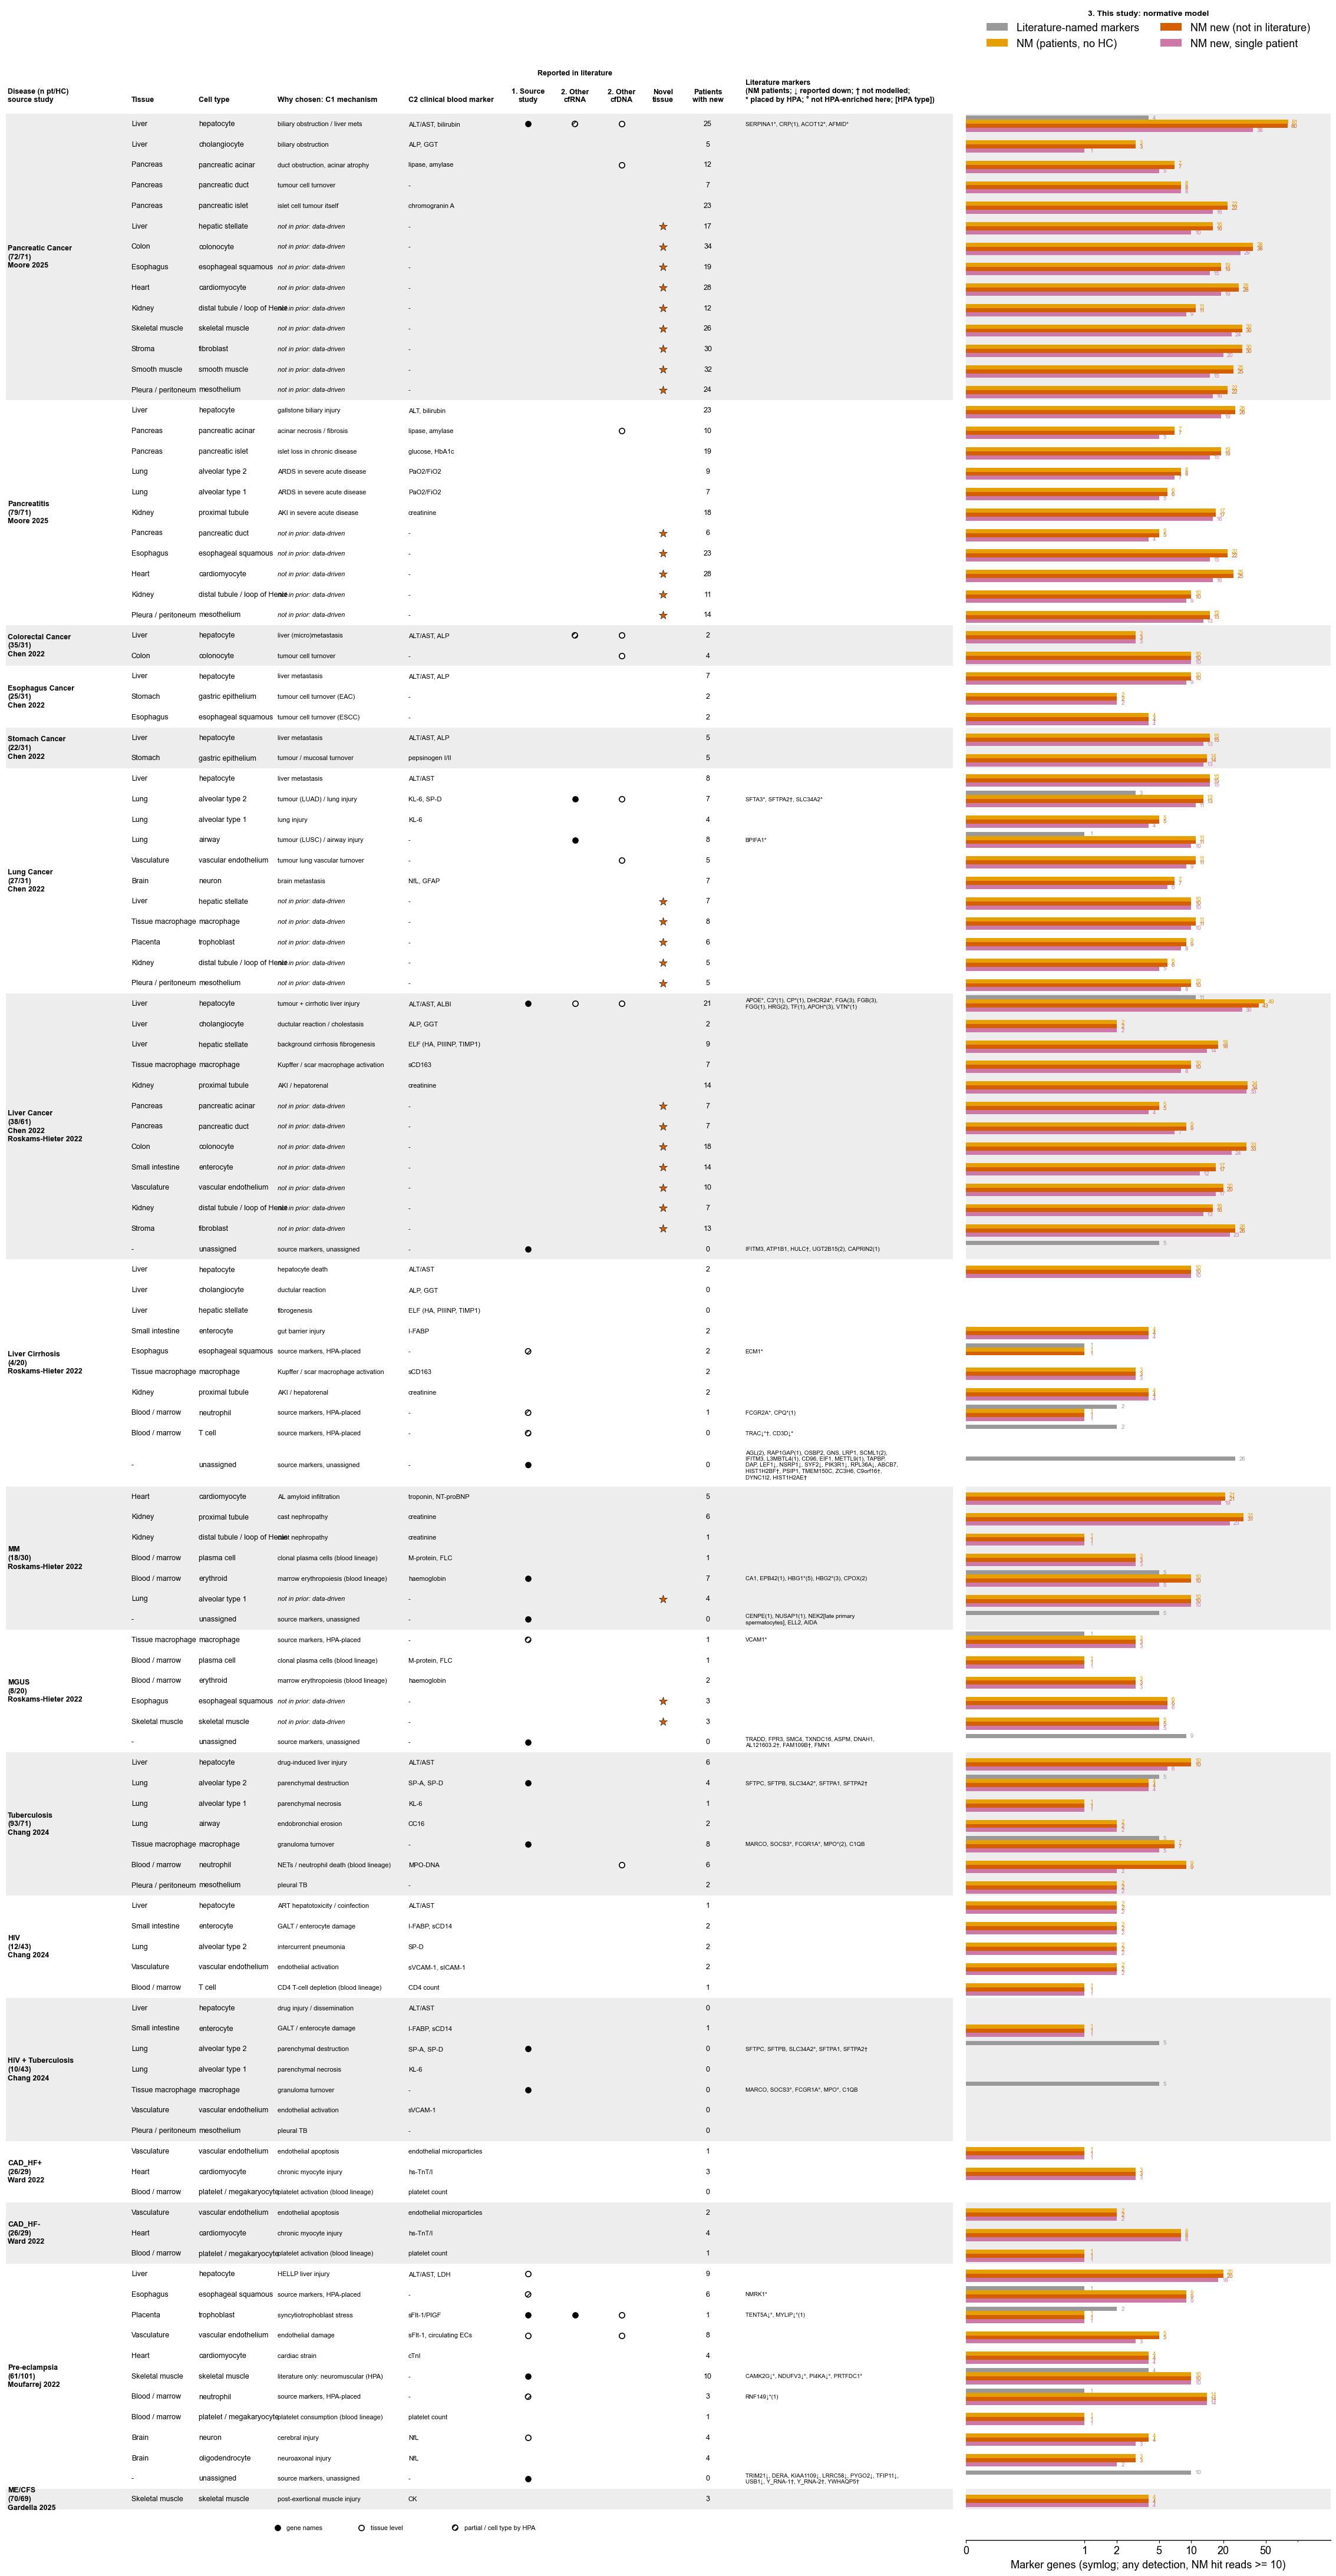

In [8]:
pri = cmp['prior'].isin(['keep', 'cond', 'blood'])
untestable = cmp[pri & (cmp['n_panel'] == 0)][['phenotype', 'panel']]
order = {p: i for i, p in enumerate(PRIOR)}
v = cmp[(pri & (cmp['n_panel'] > 0)) | cmp['novel'] | (cmp['lit_n'] > 0)].assign(
    o=lambda d: d['phenotype'].map(order), r=lambda d: d['novel'] + 2 * (d['panel'] == 'no tissue given'))
v = v.sort_values(['o', 'r'], kind='stable').reset_index(drop=True)
print('not shown, no detectable HPA marker (n_panel = 0):', list(map(tuple, untestable.values)))
missing = [k for k, nv in zip(zip(v['phenotype'], v['panel']), v['novel'])
           if k not in RATIONALE and not nv and k[1] != 'no tissue given' and not any(m[:2] == k for m in LIT_MOVED)]
assert not missing, missing
keys = list(zip(v['phenotype'], v['panel']))
gl = genes_tbl.set_index(['phenotype', 'panel', 'symbol'])['n_pat']
lit_txt = []
for k in keys:
    def lab(x):
        t = hpa_types(x)
        if k + (x,) in LIT_MOVED:
            tag = '*'
        elif k[1] == 'no tissue given':
            tag = f"[{'/'.join(t)}]" if t else ''
        else:
            tag = '' if k[1] in {panel_of_type.get(c) for c in t} else '°'
        return x + ('↓' if x in LIT_DOWN else '') + tag
    items = [f'{lab(x)}({int(gl[k + (x,)])})' if k + (x,) in gl.index and gl[k + (x,)] > 0
             else (lab(x) if k + (x,) in gl.index else f'{lab(x)}†') for x in LIT_GENES.get(k, ([], ''))[0]]
    lit_txt.append(textwrap.fill(', '.join(items), 52))
row_h = np.array([max(1.0, 0.42 * (t.count(chr(10)) + 1)) for t in lit_txt])
y = -(np.cumsum(row_h) - row_h / 2)
y = y - y.min() + row_h[-1] / 2
groups = [(ph, y[(v['phenotype'] == ph).values]) for ph in dict.fromkeys(v['phenotype'])]
half = pd.Series(row_h / 2, index=y)
bars = [('lit_n', OI['grey'], 'Literature-named markers'),
        ('nm_up_read10', OI['orange'], 'NM (patients, no HC)'),
        ('nm_new_read10', OI['vermillion'], 'NM new (not in literature)'),
        ('nm_new_single', OI['purple'], 'NM new, single patient')]
ev_cols = [('source', '1. Source\nstudy'), ('cfrna', '2. Other\ncfRNA'), ('cfdna', '2. Other\ncfDNA')]

fig = plt.figure(figsize=(29, 0.45 * row_h.sum() + 2))
gs = fig.add_gridspec(1, 2, width_ratios=[5.2, 2], wspace=0.02)
at = fig.add_subplot(gs[0])
ab = fig.add_subplot(gs[1], sharey=at)
for k, (ph, yy) in enumerate(groups):
    if k % 2 == 0:
        for ax in (at, ab):
            ax.axhspan(yy.min() - half[yy.min()], yy.max() + half[yy.max()], color='0.93', zorder=0, lw=0)
    at.text(0, yy.mean(), f"{ph}\n({len(cohort[ph]['case'])}/{len(cohort[ph]['hc'])})\n{SOURCE_STUDY[ph].replace('; ', chr(10))}", va='center',
            fontsize=FS_ANNOT_SM + 1, fontweight='bold', linespacing=1.3)
X_ORG, X_TIS, X_MEC, X_CLI, X_DOT, X_NOV, X_PAT, X_LIT = 6.6, 10.2, 14.4, 21.4, [27.8, 30.3, 32.8], 35.0, 37.4, 39.4
for yi, k, nv, npt, lt in zip(y, keys, v['novel'], v['n_carrier'], lit_txt):
    at.text(X_ORG, yi, TISSUE_OF[k[1]], va='center', fontsize=FS_ANNOT_SM + 1)
    at.text(X_TIS, yi, 'unassigned' if k[1] == 'no tissue given' else k[1], va='center', fontsize=FS_ANNOT_SM + 1)
    mec, cli = RATIONALE.get(k, ('source markers, unassigned', '-') if k[1] == 'no tissue given'
                             else ('source markers, HPA-placed', '-') if any(m[:2] == k for m in LIT_MOVED)
                             else ('not in prior: data-driven', '-'))
    at.text(X_MEC, yi, mec, va='center', fontsize=FS_ANNOT_SM, style='italic' if nv else 'normal')
    at.text(X_CLI, yi, cli, va='center', fontsize=FS_ANNOT_SM)
    if nv:
        at.scatter(X_NOV, yi, s=110, marker='*', color=OI['vermillion'], ec='k', lw=0.4, zorder=2)
    at.text(X_PAT, yi, f'{int(npt)}', ha='center', va='center', fontsize=FS_ANNOT_SM + 1)
    at.text(X_LIT, yi, lt, va='center', fontsize=FS_ANNOT_SM - 1)
    for xd, (col, _) in zip(X_DOT, ev_cols):
        lvl = EVIDENCE.get(k, {}).get(col)
        if lvl == 'genes':
            at.scatter(xd, yi, s=45, color='k', zorder=2)
        elif lvl == 'tissue':
            at.scatter(xd, yi, s=45, facecolor='w', edgecolor='k', lw=1.2, zorder=2)
        elif lvl == 'partial':
            at.scatter(xd, yi, s=45, facecolor='w', edgecolor='k', lw=1.2, hatch='////', zorder=2)
for xd, (_, name) in zip(X_DOT, ev_cols):
    at.text(xd, y.max() + 1, name, ha='center', va='bottom', fontsize=FS_ANNOT_SM + 1, fontweight='bold')
for x, h in [(0, 'Disease (n pt/HC)\nsource study'), (X_ORG, 'Tissue'), (X_TIS, 'Cell type'),
             (X_MEC, 'Why chosen: C1 mechanism'), (X_CLI, 'C2 clinical blood marker')]:
    at.text(x, y.max() + 1, h, va='bottom', fontsize=FS_ANNOT_SM + 1, fontweight='bold')
at.text(X_LIT, y.max() + 1, 'Literature markers\n(NM patients; ↓ reported down; † not modelled;\n* placed by HPA; ° not HPA-enriched here; [HPA type])', va='bottom', fontsize=FS_ANNOT_SM + 1, fontweight='bold')
for x, h in [(X_NOV, 'Novel\ntissue'), (X_PAT, 'Patients\nwith new')]:
    at.text(x, y.max() + 1, h, ha='center', va='bottom', fontsize=FS_ANNOT_SM + 1, fontweight='bold')
at.text(X_DOT[1], y.max() + 2.3, 'Reported in literature', ha='center', va='bottom', fontsize=FS_ANNOT_SM + 1, fontweight='bold')
for mk, lab, xo in [(dict(color='k'), 'gene names', 0), (dict(facecolor='w', edgecolor='k', lw=1.2), 'tissue level', 4.5),
                    (dict(facecolor='w', edgecolor='k', lw=1.2, hatch='////'), 'partial / cell type by HPA', 9.5)]:
    at.scatter(X_MEC + xo, y.min() - 1.4, s=45, **mk)
    at.text(X_MEC + xo + 0.5, y.min() - 1.4, lab, va='center', fontsize=FS_ANNOT_SM)
at.set_xlim(-0.1, 50.5)
at.set_ylim(y.min() - 2, y.max() + 3.2)
at.axis('off')

w = 0.8 / len(bars)
for k, (col, c, name) in enumerate(bars):
    yy = y + (len(bars) / 2 - 0.5 - k) * w
    ab.barh(yy, v[col], height=w, color=c, label=name, zorder=2)
    for yi, n in zip(yy, v[col]):
        if n > 0:
            ab.text(n * 1.08 + 0.05, yi, str(int(n)), va='center', fontsize=FS_ANNOT_SM - 1, color=c)
ab.set_xscale('symlog', linthresh=1)
ab.set_xlim(0, v[[b[0] for b in bars]].values.max() * 2.5)
ab.set_xticks([0, 1, 2, 5, 10, 20, 50])
ab.set_xticklabels(['0', '1', '2', '5', '10', '20', '50'])
ab.set_xlabel(f'Marker genes (symlog; any detection, NM hit reads >= {MIN_HIT_READS})')
ab.tick_params(axis='y', left=False, labelleft=False)
ab.spines['left'].set_visible(False)
ab.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False,
          title='3. This study: normative model', title_fontproperties=dict(weight='bold'))
save_fig(fig, 'lit_nm_by_tissue')
plt.show()

### 5a. Presentation versions (16:9, `Figures/ppt/`)

| Version | Content |
|---|---|
| A | One slide per disease: tissue, cell type, why chosen, literature evidence, novel star, NM bars (literature gene list dropped) |
| B | One overview slide: tissues of interest coloured (prior / novel / literature gene placed here by HPA) and sized by NM new markers (not in literature); other cells with >= `NOVEL_MIN_GENES` NM new markers as small fixed-size grey dots (presence only); black edge = tissue reported in literature |
| C | 2x2 showcase (`SHOWCASE`): A without the why-chosen column |

- Brain panels (neuron, oligodendrocyte) are dropped from both versions: brain-derived RNA is not plausible in plasma.

In [ ]:
PPT = FIG / 'ppt'
PPT.mkdir(exist_ok=True)
vp = v.assign(mec=[RATIONALE.get(k, ('source markers, unassigned' if k[1] == 'no tissue given'
                                     else 'source markers, HPA-placed' if any(m[:2] == k for m in LIT_MOVED)
                                     else 'not in prior: data-driven', '-'))[0] for k in keys],
              pri=v['prior'].isin(['keep', 'cond', 'blood']))
vp = vp[vp['panel'].map(TISSUE_OF) != 'Brain']
XMAX = vp[[b[0] for b in bars]].values.max() * 2.5
DOT = dict(genes=dict(color='k'), tissue=dict(facecolor='w', edgecolor='k', lw=1.2),
           partial=dict(facecolor='w', edgecolor='k', lw=1.2, hatch='////'))
STAR = dict(marker='*', color=OI['vermillion'], ec='k', lw=0.4)
FS = 11
ROW_IN = 0.42
COLS = [(0, 'Tissue', 16), (1.7, 'Cell type', 20), (3.8, 'Why chosen', 28)]
X_EV = [6.55, 7.2, 7.85]
X_NOV = 8.5
EV_NAMES = ['Source\nstudy', 'Other\ncfRNA', 'Other\ncfDNA']


def disease_title(ph):
    return f"{ph} ({len(cohort[ph]['case'])}/{len(cohort[ph]['hc'])} pt/HC) - {SOURCE_STUDY[ph]}"


for ph in dict.fromkeys(vp['phenotype']):
    d = vp[vp['phenotype'] == ph]
    n = max(len(d), 3)
    y = n - 1 - np.arange(len(d))
    H = ROW_IN * (n + 2.2) + 1.6
    fig = plt.figure(figsize=(13.33, H))
    at = fig.add_axes([0.01, 1 / H, 9 / 13.33, ROW_IN * (n + 2.2) / H])
    ab = fig.add_axes([0.72, 1 / H, 0.27, ROW_IN * (n + 2.2) / H], sharey=at)
    for yi, (_, r) in zip(y, d.iterrows()):
        cell = 'unassigned' if r['panel'] == 'no tissue given' else r['panel']
        for (x, _, wrap), t in zip(COLS, [TISSUE_OF[r['panel']], cell, r['mec']]):
            at.text(x, yi, textwrap.fill(t, wrap), va='center', fontsize=FS, linespacing=1.0,
                    style='italic' if x == COLS[2][0] and r['novel'] else 'normal')
        for x, (col, _) in zip(X_EV, ev_cols):
            lvl = EVIDENCE.get((ph, r['panel']), {}).get(col)
            if lvl:
                at.scatter(x, yi, s=60, zorder=2, **DOT[lvl])
        if r['novel']:
            at.scatter(X_NOV, yi, s=150, **STAR)
    for x, h, _ in COLS:
        at.text(x, n - 0.3, h, va='bottom', fontsize=FS, fontweight='bold')
    for x, h in zip(X_EV + [X_NOV], EV_NAMES + ['Novel\ntissue']):
        at.text(x, n - 0.3, h, ha='center', va='bottom', fontsize=FS - 1, fontweight='bold')
    at.text(X_EV[1], n + 0.8, 'Reported in literature', ha='center', va='bottom', fontsize=FS - 1, fontweight='bold')
    at.set_xlim(-0.05, 9)
    at.set_ylim(-0.6, n + 1.6)
    at.axis('off')
    w = 0.8 / len(bars)
    for k, (col, c, name) in enumerate(bars):
        ab.barh(y + (len(bars) / 2 - 0.5 - k) * w, d[col], height=w, color=c, label=name, zorder=2)
    ab.set_xscale('symlog', linthresh=1)
    ab.set_xlim(0, XMAX)
    ab.set_xticks([0, 1, 5, 10, 50], ['0', '1', '5', '10', '50'])
    ab.tick_params(axis='x', labelsize=FS)
    ab.tick_params(axis='y', left=False, labelleft=False)
    ab.spines['left'].set_visible(False)
    ab.set_xlabel('Marker genes (symlog)', fontsize=FS)
    for lvl, lab in zip(DOT, ['lit: gene names', 'lit: tissue level', 'lit: partial / HPA']):
        at.scatter([], [], s=60, label=lab, **DOT[lvl])
    at.scatter([], [], s=150, label='novel tissue', **STAR)
    h = [x for a in (ab, at) for x in zip(*a.get_legend_handles_labels())]
    fig.legend(*zip(*h), loc='upper center', bbox_to_anchor=(0.5, 0.3 / H), ncol=4, frameon=False, fontsize=FS - 1)
    fig.suptitle(disease_title(ph), x=0.01, y=1 - 0.2 / H, ha='left', fontsize=16, fontweight='bold')
    fig.savefig(PPT / f"A_{ph.replace(' ', '_').replace('/', '-')}.png", dpi=300, bbox_inches='tight')
    plt.show()

In [30]:
shown = set(zip(vp['phenotype'], vp['panel']))
allc = cmp[(cmp['panel'].map(TISSUE_OF) != 'Brain') & (cmp['panel'] != 'no tissue given')]
cols = [p for p in PANELS if p in set(allc['panel'])]
rows = [ph for ph in PRIOR if ph in set(allc['phenotype'])]
bm = allc.assign(
    x=lambda d: d['panel'].map({p: i for i, p in enumerate(cols)}),
    y=lambda d: d['phenotype'].map({p: len(rows) - 1 - i for i, p in enumerate(rows)}),
    rep=lambda d: [bool(EVIDENCE.get(k)) for k in zip(d['phenotype'], d['panel'])],
    cat=lambda d: np.where(d['novel'], 'novel', np.where(d['prior'].isin(['keep', 'cond', 'blood']) & (d['n_panel'] > 0), 'prior',
                  np.where([k in shown for k in zip(d['phenotype'], d['panel'])], 'lit', 'off'))))
OFF_MIN = NOVEL_MIN_GENES
bm = bm[(bm['cat'] != 'off') | (bm['nm_new_read10'] >= OFF_MIN)]
CAT = [('off', '0.75', f'not of interest,\n>= {OFF_MIN} NM new markers'), ('prior', OI['orange'], 'prior tissue of interest'),
       ('novel', OI['vermillion'], 'novel (data-driven)'), ('lit', OI['sky'], 'literature gene\nHPA-placed here')]

fig, ax = plt.subplots(figsize=(18, 6.5))
ax.set_xlim(-0.6, len(cols) - 0.4)
ax.set_ylim(-0.6, len(rows) - 0.4)
pitch = 72 * min(np.diff(ax.get_position().intervaly)[0] * fig.get_figheight() / np.ptp(ax.get_ylim()),
                 np.diff(ax.get_position().intervalx)[0] * fig.get_figwidth() / np.ptp(ax.get_xlim()))
NMAX = bm['nm_new_read10'].max()
size = lambda n: (pitch * (0.3 + 0.55 * np.log1p(np.asarray(n)) / np.log1p(NMAX))) ** 2
tis = [TISSUE_OF[p] for p in cols]
grp = np.cumsum([i == 0 or tis[i] != tis[i - 1] for i in range(len(cols))])
for g in np.unique(grp):
    xs = np.where(grp == g)[0]
    if g % 2 == 0:
        ax.axvspan(xs.min() - 0.5, xs.max() + 0.5, color='0.93', zorder=0, lw=0)
    ax.text(xs.mean(), len(rows) - 0.35, tis[xs[0]], rotation=45, ha='left', va='bottom', rotation_mode='anchor', fontsize=10)
for z, (cat, c, lab) in enumerate(CAT):
    s = bm[bm['cat'] == cat]
    ax.scatter(s['x'], s['y'], s=(0.22 * pitch) ** 2 if cat == 'off' else size(s['nm_new_read10']), color=c, ec=np.where(s['rep'], 'k', 'none'),
               lw=1.6, zorder=2 + z)
hc = [ax.scatter([], [], s=(0.22 * pitch) ** 2 if cat == 'off' else size(10), color=c, label=lab) for cat, c, lab in CAT]
hc.append(ax.scatter([], [], s=size(10), facecolor='w', ec='k', lw=1.6, label='black edge: tissue\nreported in literature'))
hs = [ax.scatter([], [], s=size(n), color='0.4', label=str(n)) for n in [0, 1, 10, 50]]
ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right', rotation_mode='anchor', fontsize=10)
ax.set_yticks([len(rows) - 1 - i for i in range(len(rows))],
              [f"{ph} ({len(cohort[ph]['case'])}/{len(cohort[ph]['hc'])})" for ph in rows], fontsize=11)
ax.grid(alpha=0.3, zorder=0)
ax.add_artist(ax.legend(handles=hc, loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, fontsize=10,
                        labelspacing=1.2, title='Tissue category', alignment='left'))
ax.legend(handles=hs, loc='lower left', bbox_to_anchor=(1.01, 0), frameon=False, fontsize=10, labelspacing=1.2,
          title='Circle size: NM new markers\n(patient-up, 0 HC, not in literature)', alignment='left')
fig.savefig(PPT / 'B_overview.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_7610/1343115426.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [31]:
SHOWCASE = [['Pancreatic Cancer', 'Pancreatitis'], ['Lung Cancer', 'Liver Cancer']]
FS_C = 10
ROW_C = 0.24
W = 20.5
C_COLS = [(0, 'Tissue', 20), (1.6, 'Cell type', 31)]
C_EV = [4.3, 4.95, 5.6]
C_NOV = 6.15
TOP, BOT, LEG = 0.25, 0.55, 0.6
nmax = [max(max(len(vp[vp['phenotype'] == ph]), 3) for ph in r) for r in SHOWCASE]
blk = [ROW_C * (n + 1.3) + TOP + BOT for n in nmax]
H = sum(blk) + LEG
fig = plt.figure(figsize=(W, H))
y0 = H
for r, b, nm in zip(SHOWCASE, blk, nmax):
    y0 -= b
    for j, ph in enumerate(r):
        d = vp[vp['phenotype'] == ph]
        n = len(d)
        y = n - 1 - np.arange(n)
        x0 = j * 10.3
        at = fig.add_axes([x0 / W, (y0 + BOT) / H, 6.4 / W, ROW_C * (nm + 1.3) / H])
        ab = fig.add_axes([(x0 + 6.5) / W, (y0 + BOT) / H, 3.5 / W, ROW_C * (nm + 1.3) / H], sharey=at)
        for yi in y[::2]:
            for ax in (at, ab):
                ax.axhspan(yi - 0.5, yi + 0.5, color='0.93', zorder=0, lw=0)
        for yi, (_, row) in zip(y, d.iterrows()):
            cell = 'unassigned' if row['panel'] == 'no tissue given' else row['panel']
            for (x, _, wrap), t in zip(C_COLS, [TISSUE_OF[row['panel']], cell]):
                at.text(x, yi, textwrap.fill(t, wrap), va='center', fontsize=FS_C, linespacing=1.0)
            for x, (col, _) in zip(C_EV, ev_cols):
                lvl = EVIDENCE.get((ph, row['panel']), {}).get(col)
                if lvl:
                    at.scatter(x, yi, s=45, zorder=2, **DOT[lvl])
            if row['novel']:
                at.scatter(C_NOV, yi, s=110, **STAR)
        for x, h, _ in C_COLS:
            at.text(x, n - 0.3, h, va='bottom', fontsize=FS_C, fontweight='bold')
        for x, h in zip(C_EV + [C_NOV], EV_NAMES + ['Novel\ntissue']):
            at.text(x, n - 0.3, h, ha='center', va='bottom', fontsize=FS_C - 1, fontweight='bold')
        at.set_xlim(-0.05, 6.4)
        at.set_ylim(-0.5, n + 0.8)
        at.axis('off')
        w = 0.8 / len(bars)
        for k, (col, cl, name) in enumerate(bars):
            ab.barh(y + (len(bars) / 2 - 0.5 - k) * w, d[col], height=w, color=cl, label=name, zorder=2)
        ab.set_xscale('symlog', linthresh=1)
        ab.set_xlim(0, XMAX)
        ab.set_xticks([0, 1, 5, 10, 50], ['0', '1', '5', '10', '50'])
        ab.tick_params(axis='x', labelsize=FS_C)
        ab.tick_params(axis='y', left=False, labelleft=False)
        ab.spines['left'].set_visible(False)
        ab.set_xlabel('Marker genes (symlog)', fontsize=FS_C)
        fig.text(x0 / W, (y0 + b) / H, disease_title(ph), va='top', fontsize=FS_C + 3, fontweight='bold')
for lvl, lab in zip(DOT, ['lit: gene names', 'lit: tissue level', 'lit: partial / HPA']):
    at.scatter([], [], s=45, label=lab, **DOT[lvl])
at.scatter([], [], s=110, label='novel tissue', **STAR)
h = [x for a in (ab, at) for x in zip(*a.get_legend_handles_labels())]
fig.legend(*zip(*h), loc='upper center', bbox_to_anchor=(0.5, LEG / H), ncol=4, frameon=False, fontsize=FS_C)
fig.savefig(PPT / 'C_showcase.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_7610/974707841.py:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6. Cell-type marker enrichment (disease x panel, standard ORA)

- Per disease, pool all patients' signal into one gene set and run over-representation analysis (ORA) against HPA panels.
- Signal set = genes up (BH q < 0.05, reads >= `MIN_HIT_READS`) in >= 1 patient of that disease and in 0 same-batch HC (over all engine genes).
- Universe = engine genes detected at least once in that disease's comparison samples (patients + same-batch HC).
- Panel = Section 2 HPA panel (after plasma specificity filter) ∩ universe.
- One-sided Fisher exact (over-representation), BH correction over all cells. Expected = signal size x panel size / universe size.
- Figure: rows = cell-type panels (grouped by tissue, alternating shading), columns = diseases. Dot size = signal set ∩ panel gene count, color = -log10(BH q).
  - Dashed circle = prior tissue of interest (`PRIOR` keep/cond/blood; empty dashed circle only if observed 0).
- PPT version (B layout: diseases as rows, brain panels dropped): `Figures/ppt/D_enrichment.png`.
- Limitations: no detection-rate matching, so tissues abundant in plasma (liver, blood cells) may be favored; ignores inter-gene correlation. Not used for novel calls (4a).

In [34]:
ALL_CNT_CACHE = OUT / 'all_counts.npz'
if ALL_CNT_CACHE.exists():
    C_all = sp.load_npz(ALL_CNT_CACHE).tocsr()
else:
    A = ad.read_h5ad(config.H5AD_PATH, backed='r')
    si = A.obs_names.get_indexer(names)
    o = np.argsort(si)
    X = sp.csr_matrix(A.X[si[o]])[:, A.var_names.get_indexer(genes)]
    C_all = X[np.argsort(o)].tocsr()
    sp.save_npz(ALL_CNT_CACHE, C_all)

pn_order = [p for p in PANELS if PANELS[p]]
ens_set = {p: set(panel_tbl.loc[panel_tbl['panel'] == p, 'col']) for p in pn_order}
enr = []
for ph, c in cohort.items():
    rc, rh = row_of[c['case']].values, row_of[c['hc']].values
    universe = np.asarray((C_all[np.concatenate([rc, rh])] > 0).sum(0)).ravel() > 0
    hit = (UP[rc] & (C_all[rc] >= MIN_HIT_READS).toarray()).any(0) & ~UP[rh].any(0) & universe
    n_u, n_s = universe.sum(), hit.sum()
    for p in pn_order:
        pm = np.zeros(len(genes), bool)
        pm[list(ens_set[p])] = True
        pm &= universe
        k, n_p = int((hit & pm).sum()), int(pm.sum())
        enr.append(dict(phenotype=ph, panel=p, prior=PRIOR[ph].get(p, 'off'), obs=k, exp=n_s * n_p / n_u,
                        n_signal=n_s, n_panel=n_p, n_universe=n_u,
                        p=fisher_exact([[k, n_p - k], [n_s - k, n_u - n_p - n_s + k]], alternative='greater')[1]))
enr = pd.DataFrame(enr)
enr['q'] = false_discovery_control(enr['p'])
enr['log2_oe'] = np.log2((enr['obs'] + 0.5) / (enr['exp'] + 0.5))
enr.to_csv(OUT / 'disease_tissue_enrichment.csv', index=False)
print(enr.groupby('phenotype')[['n_signal', 'n_universe']].first().to_string())

ph_order = list(PRIOR)
tis_order = list(dict.fromkeys(TISSUE_OF[p] for p in pn_order))
pn_rows = sorted(pn_order, key=lambda p: tis_order.index(TISSUE_OF[p]))
d = enr.assign(x=enr['phenotype'].map(ph_order.index), y=enr['panel'].map(pn_rows.index))
size = lambda n: 72 * np.sqrt(np.maximum(n, 1))
fig, ax = plt.subplots(figsize=(0.62 * len(ph_order) + 7, 0.42 * len(pn_rows) + 3))
X0 = -0.36
for k, t in enumerate(tis_order):
    yy = [pn_rows.index(p) for p in pn_rows if TISSUE_OF[p] == t]
    if k % 2 == 0:
        ax.add_patch(Rectangle((X0, min(yy) - 0.5), 1 - X0, len(yy), transform=ax.get_yaxis_transform(),
                               color='0.92', lw=0, zorder=0, clip_on=False))
    ax.text(X0 + 0.01, np.mean(yy), t, transform=ax.get_yaxis_transform(), ha='left', va='center',
            fontsize=FS_ANNOT_SM + 5, fontweight='bold')
dd = d[d['obs'] > 0]
sc = ax.scatter(dd['x'], dd['y'], s=size(dd['obs']), c=-np.log10(dd['q']), cmap='Reds', vmin=0,
                vmax=max(2, -np.log10(dd['q']).max()), edgecolors='0.5', linewidths=0.3, zorder=2)
pr = d[d['prior'] != 'off']
ax.scatter(pr['x'], pr['y'], s=size(pr['obs']) * 1.6, facecolors='none', edgecolors='k', linewidths=1.1,
           linestyles='--', zorder=3)
ax.set_xticks(range(len(ph_order)))
ax.set_xticklabels([f"{p} ({len(cohort[p]['case'])}/{len(cohort[p]['hc'])})" for p in ph_order], rotation=90)
ax.set_yticks(range(len(pn_rows)))
ax.set_yticklabels(pn_rows)
ax.tick_params(axis='y', length=0)
ax.set_xlim(-0.5, len(ph_order) - 0.5)
ax.set_ylim(len(pn_rows) - 0.5, -0.5)
cb = plt.colorbar(sc, ax=ax, fraction=0.03, shrink=0.35, anchor=(0, 1), label='-log10 BH q')
cb.ax.axhline(-np.log10(0.05), color='k', lw=1)
for n in [1, 10, 50]:
    ax.scatter([], [], s=size(n), c='0.6', label=f'{n} NM genes')
ax.scatter([], [], s=size(10) * 1.6, facecolors='none', edgecolors='k', linewidths=1.1, linestyles='--',
           label='prior tissue of interest')
ax.legend(loc='lower left', bbox_to_anchor=(1.01, 0), frameon=False, labelspacing=1.6)
plt.tight_layout()
save_fig(fig, 'disease_tissue_enrichment')
plt.show()
enr[enr['p'] < 0.05].sort_values('p').round(3)

                    n_signal  n_universe
phenotype                               
CAD_HF+                  138       19261
CAD_HF-                  243       19277
Colorectal Cancer        683       19322
Esophagus Cancer         329       19406
HIV                      465       19131
HIV + Tuberculosis        43       19039
Liver Cancer            2607       19617
Liver Cirrhosis          199       18587
Lung Cancer             1747       19408
ME/CFS                   649       19022
MGUS                     387       18919
MM                      1986       19348
Pancreatic Cancer       1680       19033
Pancreatitis            1418       18987
Pre-eclampsia            815       19212
Stomach Cancer          1564       19355
Tuberculosis             651       19635


/tmp/ipykernel_7610/3645524155.py:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,phenotype,panel,prior,obs,exp,n_signal,n_panel,n_universe,p,q,log2_oe
0,Pancreatic Cancer,hepatocyte,keep,81,17.036,1680,193,19033,0.000,0.000,2.217
246,MM,colonocyte,off,76,18.990,1986,185,19348,0.000,0.000,1.973
247,MM,enterocyte,off,43,9.546,1986,93,19348,0.000,0.000,2.114
352,HIV,neutrophil,off,19,1.847,465,76,19131,0.000,0.000,3.054
500,ME/CFS,plasma cell,off,11,1.535,649,45,19022,0.000,0.000,2.498
...,...,...,...,...,...,...,...,...,...,...,...
233,Liver Cirrhosis,platelet / megakaryocyte,off,2,0.332,199,31,18587,0.043,0.245,1.587
456,Pre-eclampsia,colonocyte,off,13,7.678,815,181,19212,0.045,0.252,0.723
18,Pancreatic Cancer,distal tubule / loop of Henle,off,11,6.267,1680,71,19033,0.046,0.253,0.765
313,Tuberculosis,macrophage,keep,7,3.282,651,99,19635,0.046,0.253,0.988


In [40]:
cols_e = [p for p in pn_rows if TISSUE_OF[p] != 'Brain']
de = enr[enr['panel'].isin(cols_e)].assign(x=lambda d: d['panel'].map(cols_e.index),
                                           y=lambda d: d['phenotype'].map(lambda p: len(ph_order) - 1 - ph_order.index(p)))
fig, ax = plt.subplots(figsize=(18, 6.5))
ax.set_xlim(-0.6, len(cols_e) - 0.4)
ax.set_ylim(-0.6, len(ph_order) - 0.4)
pitch = 72 * min(np.diff(ax.get_position().intervaly)[0] * fig.get_figheight() / np.ptp(ax.get_ylim()),
                 np.diff(ax.get_position().intervalx)[0] * fig.get_figwidth() / np.ptp(ax.get_xlim()))
NMAX = de['obs'].max()
size_e = lambda n: (pitch * (0.3 + 0.55 * np.log1p(np.asarray(n)) / np.log1p(NMAX))) ** 2
ring = lambda n: (np.sqrt(size_e(n)) + 5) ** 2
tis = [TISSUE_OF[p] for p in cols_e]
grp = np.cumsum([i == 0 or tis[i] != tis[i - 1] for i in range(len(cols_e))])
for g in np.unique(grp):
    xs = np.where(grp == g)[0]
    if g % 2 == 0:
        ax.axvspan(xs.min() - 0.5, xs.max() + 0.5, color='0.93', zorder=0, lw=0)
    ax.text(xs.mean(), len(ph_order) - 0.35, tis[xs[0]], rotation=45, ha='left', va='bottom', rotation_mode='anchor', fontsize=10)
dd = de[de['obs'] > 0]
sc = ax.scatter(dd['x'], dd['y'], s=size_e(dd['obs']), c=-np.log10(dd['q']), cmap='Reds', vmin=0,
                vmax=max(2, -np.log10(dd['q']).max()), edgecolors='0.5', linewidths=0.3, zorder=2)
pr = de[de['prior'] != 'off']
ax.scatter(pr['x'], pr['y'], s=ring(pr['obs']), facecolors='none', edgecolors='k', linewidths=1.1,
           linestyles='--', zorder=3)
ax.set_xticks(range(len(cols_e)), cols_e, rotation=45, ha='right', rotation_mode='anchor', fontsize=10)
ax.set_yticks([len(ph_order) - 1 - i for i in range(len(ph_order))],
              [f"{ph} ({len(cohort[ph]['case'])}/{len(cohort[ph]['hc'])})" for ph in ph_order], fontsize=11)
ax.grid(alpha=0.3, zorder=0)
cax = ax.inset_axes([1.02, 0.55, 0.012, 0.45])
cb = fig.colorbar(sc, cax=cax, label='-log10 BH q')
cb.ax.axhline(-np.log10(0.05), color='k', lw=1)
hs = [ax.scatter([], [], s=size_e(n), color='0.6', label=str(n)) for n in [1, 10, 50]]
hs.append(ax.scatter([], [], s=ring(10), facecolors='none', edgecolors='k', linewidths=1.1,
                     linestyles='--', label='prior tissue\nof interest'))
ax.legend(handles=hs, loc='lower left', bbox_to_anchor=(1.01, 0), frameon=False, fontsize=10, labelspacing=1.2,
          title='Circle size: NM genes in panel', alignment='left')
fig.savefig(PPT / 'D_enrichment.png', dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_7610/4187931119.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 7. Where each literature marker was captured

- All literature markers have detection rate >= 10%, so both criteria give the same result (only `read10` shown).

In [10]:
genes_tbl[genes_tbl['lit']][['phenotype', 'panel', 'symbol', 'in_panel', 'nm_up',
                             'n_pat', 'n_case', 'n_hc', 'detect']].round(3)

,phenotype,panel,symbol,in_panel,nm_up,n_pat,n_case,n_hc,detect
0,Pancreatic Cancer,hepatocyte,SERPINA1,False,False,0,72,0,1.000
1,Pancreatic Cancer,hepatocyte,CRP,True,True,1,72,0,0.308
2,Pancreatic Cancer,hepatocyte,ACOT12,True,False,0,72,0,0.133
3,Pancreatic Cancer,hepatocyte,AFMID,False,False,0,72,0,0.615
16680,Lung Cancer,alveolar type 2,SFTA3,False,False,0,27,0,0.052
...,...,...,...,...,...,...,...,...,...
49891,Pre-eclampsia,no tissue given,KIAA1109,False,False,0,61,0,0.994
49892,Pre-eclampsia,no tissue given,LRRC58,False,False,0,61,0,0.944
49893,Pre-eclampsia,no tissue given,PYGO2,False,False,0,61,0,0.907
49894,Pre-eclampsia,no tissue given,TFIP11,False,False,0,61,0,0.981


## 8. 1-patient hit genes -- sample-level cases invisible to group analysis

- Target: under `read10`, tissue-of-interest (keep/cond) panel genes BH up (reads >= `MIN_HIT_READS`) in **only 1 patient**, 0 same-batch HC, not literature-named markers.

| Column | Meaning |
|---|---|
| `reads`, `cpm`, `Z` | That patient's raw reads, CPM, NM Z |
| `hc_pool_detect` | Fraction with read > 0 in the full HC pool (592) |
| `hc_pool_max_cpm` | Max CPM in the full HC pool. Patient CPM above this is outside the healthy range |
| `pat_n_up` / `pat_n_up_hc_pct` | That patient's total up-gene count and its percentile in the HC pool distribution. High values suggest part of a "globally outlying sample" |

In [11]:
prior_cells = set(map(tuple, tbl.loc[tbl['prior'].isin(['keep', 'cond']), key].values))
hc_up = n_up.loc[hm['sample']].values
s1 = genes_tbl[genes_tbl['nm_up'] & genes_tbl['in_panel'] & ~genes_tbl['lit']
               & (genes_tbl['n_pat'] == 1)]
s1 = s1[[k in prior_cells for k in zip(s1['phenotype'], s1['panel'])]].copy()
s1['sample'] = s1['hit_samples']
s1['reads'] = [cnt.at[s, g] for s, g in zip(s1['sample'], s1['gene'])]
s1['cpm'] = [cpm.at[s, g] for s, g in zip(s1['sample'], s1['gene'])]
s1['Z'] = [Z_all[row_of[s], pd.Index(genes).get_loc(g)] for s, g in zip(s1['sample'], s1['gene'])]
s1['hc_pool_detect'] = [(cnt.loc[hm['sample'], g] > 0).mean() for g in s1['gene']]
s1['hc_pool_max_cpm'] = [cpm.loc[hm['sample'], g].max() for g in s1['gene']]
s1['pat_n_up'] = n_up.loc[s1['sample']].values
s1['pat_n_up_hc_pct'] = [(hc_up < x).mean() * 100 for x in s1['pat_n_up']]
s1 = s1.sort_values(['phenotype', 'panel', 'reads'], ascending=[True, True, False])
s1.to_csv(OUT / 'single_patient_hits.csv', index=False)
s1[['phenotype', 'panel', 'symbol', 'acute_phase', 'sample', 'reads', 'cpm', 'Z', 'detect', 'hc_pool_detect',
    'hc_pool_max_cpm', 'pat_n_up', 'pat_n_up_hc_pct']].round(2)

,phenotype,panel,symbol,acute_phase,sample,reads,cpm,Z,detect,hc_pool_detect,hc_pool_max_cpm,pat_n_up,pat_n_up_hc_pct
42385,CAD_HF+,cardiomyocyte,ASB15,False,SRX16239444,32.000000,1.32,5.28,0.18,0.06,37.46,8,96.62
42250,CAD_HF+,cardiomyocyte,MB,False,SRX16239463,17.000000,1.05,10.00,0.13,0.05,13.98,4,95.44
42308,CAD_HF+,cardiomyocyte,FITM1,False,SRX16239443,16.000000,2.94,4.39,0.31,0.20,10.47,10,97.13
42202,CAD_HF+,vascular endothelium,HOXD3,False,SRX16239472,32.000000,9.29,4.37,0.31,0.26,19.05,7,96.45
45345,CAD_HF-,cardiomyocyte,MYH7,False,SRX16239397,788.489990,39.10,5.19,0.38,0.16,336.01,11,97.30
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32624,Tuberculosis,macrophage,PIK3R2,False,SRR28476094,107.910004,23.88,3.78,0.99,0.64,100.95,71,99.16
32672,Tuberculosis,macrophage,HAVCR2,False,SRR28476062,57.000000,21.72,4.85,0.95,0.87,153.76,5,95.95
32701,Tuberculosis,macrophage,ENSG00000289692,False,SRR28477218,10.530000,19.08,4.45,0.95,0.78,89.59,35,98.82
34356,Tuberculosis,mesothelium,SMTNL2,False,SRR28476510,18.000000,10.66,8.15,0.12,0.12,9.54,8,96.62


### 8a. 1-patient hit genes: observed HC pool vs model-predicted HC pool vs that patient's conditional distribution

**Selection criteria** (same as Section 8 table; one gene = one slot)

| Condition | Value |
|---|---|
| Tissue | Tissue-of-interest panels (keep/cond) of that disease, HPA official cell type / group enriched |
| hit | Only 1 patient with within-sample BH q < 0.05, Z > 0, reads >= `MIN_HIT_READS` |
| Control | 0 same-batch HC with BH up |
| New | Not a literature-named marker |
| Display | One figure per disease: top `N_PER` by `hit_ratio` (patient reads / 99.5% quantile of conditional distribution), grouped by panel |

**Figure layout** (one per disease; x = hit genes (parentheses = patient P1, P2, ...), y = log10(CPM + 1))
- Color = patient (violin and star share color; SRR numbers in the Patient legend on the right).
- Violin = healthy distribution predicted by the engine from that patient's covariates (NB + batch random effect `tau2`, `N_DRAW` draws).
- Black horizontal line = 99.5% quantile of that conditional distribution.
- Gray dots = observed values of all patients of the same disease (shows whether other patients are mostly 0 for that gene).
- Star = observed value of the hit patient. The further the star sits above the violin and gray dots, the more that single patient deviates.
- Model calibration check (HC observed vs predicted detection rate) is in the PPC figure below.

In [12]:
from numpy.polynomial.hermite_e import hermegauss
from scipy.stats import nbinom

from MixedEffectsModeling.core.model_engine_mixed import NormativeModelEngineMixed
from MixedEffectsModeling.validation.lobo_engine import load_full_data


def nb_params(engine, X, g):
    rec = engine.genes[g]
    Xa = np.column_stack([np.ones(len(X)), X])
    if rec.route == 'pool':
        rg = engine.rare_glm
        mult = np.exp(X @ rg['beta'][1:])
        if rg.get('mult_lo') is not None:
            mult = np.clip(mult, rg['mult_lo'], rg['mult_hi'])
        mu = (rec.mean_hc + rg['eps']) * np.exp(rg['beta'][0]) * mult
        alpha = np.full(len(X), 1e-8 if rg['family'] == 'poisson' else rg['alpha'])
        tau2 = 0.0 if rg['family'] == 'poisson' else rg.get('tau2', 0.0)
    else:
        mu = np.exp(Xa @ np.nan_to_num(rec.mu_coef, nan=0.0))
        if not np.all(np.isnan(rec.disp_coef)):
            alpha = np.exp(-Xa @ np.nan_to_num(rec.disp_coef, nan=0.0))
        elif rec.trend_alpha is not None:
            alpha = np.full(len(X), rec.trend_alpha)
        else:
            alpha = np.full(len(X), engine.alpha_fn(float(mu.mean())))
        tau2 = rec.tau2
    return np.clip(mu, 1e-6, 1e8), alpha, float(tau2), rec.route


COND_CACHE = OUT / 'single_hit_conditional.pkl'
if COND_CACHE.exists():
    cond, hc_par = pickle.load(open(COND_CACHE, 'rb'))
else:
    engine = NormativeModelEngineMixed.load(config.ENGINE_DIR)
    data = load_full_data()
    pos = pd.Series(np.arange(len(data['names'])), index=data['names'])
    ip, ih = pos[s1['sample']].values, pos[hm['sample']].values
    Xp = engine.scaler.transform(engine.covariates.transform(data['obs'][ip], data['Y'][ip]))
    Xh = engine.scaler.transform(engine.covariates.transform(data['obs'][ih], data['Y'][ih]))
    rows, hc_par = [], {}
    for k, (smp, g) in enumerate(zip(s1['sample'], s1['gene'])):
        mu, alpha, tau2, route = nb_params(engine, Xp[k:k + 1], g)
        rows.append(dict(sample=smp, gene=g, route=route, mu=mu[0], alpha=alpha[0], tau2=tau2))
        if g not in hc_par:
            hc_par[g] = nb_params(engine, Xh, g)[:3]
    cond = pd.DataFrame(rows)
    pickle.dump((cond, hc_par), open(COND_CACHE, 'wb'))


def cond_cdf(y, mu, alpha, tau2, n_nodes=7):
    nodes, w = hermegauss(n_nodes)
    w = w / w.sum()
    n = 1.0 / alpha
    sd = np.sqrt(max(tau2, 0.0))
    return sum(wi * nbinom.cdf(y, n, n / (n + mu * np.exp(sd * nd))) for nd, wi in zip(nodes, w))


def cond_draw(mu, alpha, tau2, rng):
    n = 1.0 / np.asarray(alpha, dtype=float)
    m = np.asarray(mu, dtype=float) * np.exp(rng.normal(0, np.sqrt(max(tau2, 0.0)), np.shape(mu)))
    return rng.negative_binomial(n, n / (n + m))


s1 = s1.drop(columns=[c for c in ['mu', 'alpha', 'tau2', 'route'] if c in s1]).merge(cond, on=['sample', 'gene'], how='left')
s1['cond_hi'] = [int(np.argmax(cond_cdf(np.arange(int(max(r.reads, 50)) + 1), r.mu, r.alpha, r.tau2) >= 0.995))
                 for r in s1.itertuples()]
s1['cond_tail_p'] = [1 - cond_cdf(r.reads - 1, r.mu, r.alpha, r.tau2) for r in s1.itertuples()]
s1['hit_ratio'] = s1['reads'] / np.maximum(s1['cond_hi'], 1)
s1['above_hc_pool_max'] = s1['cpm'] > s1['hc_pool_max_cpm']
s1['hc_detect_obs'] = s1['hc_pool_detect']
s1['hc_detect_pred'] = [float(np.mean(1 - cond_cdf(0, *hc_par[g]))) for g in s1['gene']]
s1['hc_detect_ratio'] = s1['hc_detect_pred'] / s1['hc_detect_obs'].clip(lower=1e-3)
s1.to_csv(OUT / 'single_patient_hits.csv', index=False)
print('HC detection, predicted / observed (median over hit genes):', round(s1['hc_detect_ratio'].median(), 2))
s1[['phenotype', 'panel', 'symbol', 'sample', 'reads', 'mu', 'cond_hi', 'hit_ratio', 'cond_tail_p', 'Z',
    'hc_detect_obs', 'hc_detect_pred', 'above_hc_pool_max']].sort_values('hit_ratio', ascending=False).round(3).head(30)

HC detection, predicted / observed (median over hit genes): 1.03


,phenotype,panel,symbol,sample,reads,mu,cond_hi,hit_ratio,cond_tail_p,Z,hc_detect_obs,hc_detect_pred,above_hc_pool_max
378,Pancreatitis,alveolar type 2,ITGB6,SRR29804074,625.000000,0.013,1,625.000,0.00,8.843,0.059,0.064,True
410,Pancreatitis,pancreatic acinar,REG3G,SRR29804048,151.000000,0.025,1,151.000,0.00,7.242,0.056,0.059,True
518,Tuberculosis,macrophage,PIK3R2,SRR28476094,107.910004,12.137,0,107.910,0.01,3.784,0.635,0.682,False
432,Pancreatitis,proximal tubule,SLC17A1,SRR29803997,204.000000,0.020,2,102.000,0.00,6.173,0.025,0.022,True
431,Pancreatitis,proximal tubule,SLC17A1,SRR29803997,204.000000,0.020,2,102.000,0.00,6.173,0.025,0.022,True
391,Pancreatitis,hepatocyte,SLC17A1,SRR29803997,204.000000,0.020,2,102.000,0.00,6.173,0.025,0.022,True
392,Pancreatitis,hepatocyte,SLC17A1,SRR29803997,204.000000,0.020,2,102.000,0.00,6.173,0.025,0.022,True
446,Pre-eclampsia,cardiomyocyte,MLIP,SRR17333155,364.000000,0.059,4,91.000,0.00,5.982,0.145,0.149,False
309,Pancreatic Cancer,hepatocyte,UGT1A9,SRR29803891,314.227997,0.053,4,78.557,0.00,4.980,0.030,0.025,True
409,Pancreatitis,pancreatic acinar,ENSG00000268655,SRR29804016,152.000000,0.028,2,76.000,0.00,5.042,0.022,0.020,True


In [13]:
N_PER = 30
N_DRAW = 2000
rng = np.random.default_rng(0)
for ph in PRIOR:
    sub = s1[s1['phenotype'] == ph].sort_values('hit_ratio', ascending=False).head(N_PER)
    if sub.empty:
        continue
    sub = sub.sort_values(['panel', 'hit_ratio'], ascending=[True, False]).reset_index(drop=True)
    pid = {x: f'P{i + 1}' for i, x in enumerate(dict.fromkeys(sub.sort_values('sample')['sample']))}
    cases = cohort[ph]['case']
    pal = [OI[k] for k in ['orange', 'blue', 'vermillion', 'green', 'purple', 'sky', 'yellow', 'black']]
    if len(pid) > len(pal):
        pal = [plt.cm.tab20(i % 20) for i in range(len(pid))]
    col = {x: pal[i] for i, x in enumerate(pid)}
    n_slot = max(len(sub), 8)
    pad = (n_slot - len(sub)) / 2
    fig, ax = plt.subplots(figsize=(0.5 * n_slot + 2, 5))
    viol = [np.log10(cond_draw(np.full(N_DRAW, r.mu), np.full(N_DRAW, r.alpha), r.tau2, rng) / libsize[r.sample] * 1e6 + 1)
            + rng.normal(0, 1e-3, N_DRAW) for r in sub.itertuples()]
    vp = ax.violinplot(viol, positions=range(len(sub)), widths=0.8, showextrema=False, bw_method=0.3)
    for b, r in zip(vp['bodies'], sub.itertuples()):
        b.set_facecolor(col[r.sample])
        b.set_edgecolor('none')
        b.set_alpha(0.35)
    for j, r in enumerate(sub.itertuples()):
        y = np.log10(cpm.loc[cases, r.gene].values + 1)
        ax.scatter(j + rng.uniform(-0.18, 0.18, len(y)), y, s=5, color=OI['grey'], alpha=0.7, lw=0, zorder=2)
        hi = np.log10(r.cond_hi / libsize[r.sample] * 1e6 + 1)
        ax.plot([j - 0.3, j + 0.3], [hi, hi], color='k', lw=1, zorder=3)
        ax.scatter([j], [np.log10(r.cpm + 1)], s=110, marker='*', color=col[r.sample], ec='k', lw=0.5, zorder=4)
    for k, (pn, g) in enumerate(sub.groupby('panel', sort=False)):
        if k % 2 == 0:
            ax.axvspan(g.index.min() - 0.5, g.index.max() + 0.5, color='0.93', lw=0, zorder=0)
        ax.text(g.index.to_series().mean(), 1.01, textwrap.fill(pn, max(6, 4 * len(g)), break_long_words=False), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=FS_ANNOT_SM + 1, fontweight='bold')
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels([f'{r.symbol} ({pid[r.sample]})' for r in sub.itertuples()], rotation=90)
    ax.set_xlim(-0.6 - pad, len(sub) - 0.4 + pad)
    ax.set_ylabel('log10(CPM + 1)')
    hs = [plt.Line2D([], [], marker='*', ls='', ms=11, mfc='w', mec='k', mew=0.5),
          plt.Rectangle((0, 0), 1, 1, color='0.6', alpha=0.35), plt.Line2D([], [], color='k', lw=1),
          plt.Line2D([], [], marker='o', ls='', ms=3.5, color=OI['grey'])]
    lb = ['hit patient, observed', 'healthy expectation\n(that patient)', 'conditional 99.5%', f'all patients (n = {len(cases)})']
    hs += [plt.Line2D([], [], marker='*', ls='', ms=11, mfc=col[x], mec='k', mew=0.5) for x in pid]
    lb += [f'{pid[x]} {x}' for x in pid]
    ax.legend(hs, lb, loc='upper left', bbox_to_anchor=(1.01, 1.1), frameon=False, fontsize=FS_ANNOT_SM,
              ncol=1 + len(lb) // 12)
    n_all = (s1['phenotype'] == ph).sum()
    ax.set_title(f'{ph}: single-patient tissue hits ({len(sub)} of {n_all}, top by reads / conditional 99.5%)',
                 fontsize=FS_ANNOT_SM + 2, fontweight='bold', pad=34)
    plt.tight_layout()
    save_fig(fig, 'single_patient_hits_strip_' + ''.join(ch if ch.isalnum() or ch == '-' else '_' for ch in ph.replace('+', 'plus')))
    plt.show()

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(s1['hc_detect_obs'], s1['hc_detect_pred'], s=18, color=np.where(s1['above_hc_pool_max'], OI['vermillion'], OI['grey']),
           ec='k', lw=0.3)
lim = max(s1['hc_detect_obs'].max(), s1['hc_detect_pred'].max()) * 1.05
ax.plot([0, lim], [0, lim], ls='--', color='k', lw=0.8)
ax.set_xlabel('HC pool detection rate, observed')
ax.set_ylabel('HC pool detection rate, model-predicted')
ax.set_title('Single-patient hit genes (red: patient above HC pool max)', fontsize=FS_ANNOT_SM)
plt.tight_layout()
save_fig(fig, 'single_patient_hits_hc_ppc')
plt.show()

/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/tmp/ipykernel_51571/2904715517.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt